<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_NoiseAdversarial_Wang2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Noisy variational quantum classifier under FGSM / PGD / EOT attacks: Wang et al. (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Haoran Wang, Shaoliang Ye, Shaowei Wang, Hanyi Wang, Zhenbo Shi and Wei Yang, "Decoupling the Dual Impact of NISQ Noise on Quantum Adversarial Robustness",
> *Entropy* **28**(7), 719, 2026. DOI 10.3390/e28070719

The paper asks a security question: when a quantum classifier runs on noisy (NISQ) hardware, does the device noise protect it against adversarial examples ("noise as a free defence"), or does it open a new attack surface? It answers with a **four-path evaluation protocol** that separates the noise assumed when the attack is *generated* from the noise present at *inference*, tested on a 4-qubit variational quantum classifier (VQC) with depolarizing noise `p` in [0, 0.3], on four small datasets, with FGSM, PGD and expectation-over-transformation (EOT) attacks. The paper publishes no code ("the released implementation" is mentioned but no link is given), so everything below is written from the text, with the stack the paper names (PennyLane, scikit-learn).

**What the notebook does.** It builds the datasets, the 4-qubit VQC (angle encoding, one `StronglyEntanglingLayers` block, `<Z_0>` readout) with a depolarizing channel on every wire before the measurement, trains one noise-matched model per `p`, runs the four attacks along the four paths A to D for six noise levels and several seeds, builds the cross-noise transferability matrices, adds classical baselines on the identical 4-angle inputs, and ends with a claim-by-claim comparison with the paper's numbers (Tables 1, 4, 5, 6, 7, Figure 3, Figure 4).

**How to run.** Google Colab, CPU runtime, `Runtime -> Run all`. With `FAST_MODE = True` (2 seeds, 40 training steps, K = 4, at most 120 test points) it takes a few minutes; with `FAST_MODE = False` it follows the paper's budgets (5 seeds, 120 steps, K = 16, whole test splits) and takes roughly half an hour on a laptop CPU. No quantum hardware, no account and no API key are needed (the optional Hugging Face token is only used if the OpenML copy of MNIST cannot be reached; for a gated dataset a reader must put their own token in Colab *Secrets* under the name `HF_TOKEN`).

**What you get at the end.** The paper's Table 4 / 5 / 6 / 7 and Figure 3 / 4 redrawn from your own runs, an explicit verdict ("reproduced", "partially", "not reached", "cannot be checked") for each checkable claim, and an explanation of *why* the noise behaves the way it does in this model.

## The paper in one page

**Problem.** Is ambient NISQ noise a passive defence against adversarial examples on a quantum classifier, or can an adversary exploit it? The classical inputs of the four datasets are angle-encoded, so an adversary perturbs the encoded angles.

**Model (Fig. 1, Table 2).** 4 qubits. Feature `x_j` is the angle of `RY(x_j)` on qubit `j`; one `StronglyEntanglingLayers` block (trainable `Rot` gates and CNOT ring); a single-qubit depolarizing channel $D_p(\rho) = (1-p)\rho + \tfrac{p}{3}(X\rho X + Y\rho Y + Z\rho Z)$ of strength `p` on every wire immediately before the measurement of `<Z_0>`; the label follows from thresholding the (rescaled) expectation value. Clean circuits use a state-vector simulator, noisy ones a mixed-state simulator, all with 1024 shots.

**Training (Sec. 5.6).** 120 steps, mini-batch 16, learning rate 0.08, PennyLane gradient descent. For every non-zero `p` a **separate model is retrained with the channel active** ("noise-matched retraining").

**Data (Sec. 5.1, Table 1).** Four binary tasks reduced to four features: two-moons (400 samples, noise 0.15, zero-padded to 4), breast cancer (569, PCA 4), Pima Indians Diabetes from OpenML (768, PCA 4) and MNIST 0 vs 1 (about 1400, PCA 4); all mapped to [-pi, pi]; stratified 70 : 30 split; 5 seeds.

**Attacks (Sec. 4.3, Table 3).** White-box, in the encoded angle space with an $\ell_\infty$ budget of 0.3: FGSM (1 step), PGD (10 steps of 0.02), PGD-EOT (gradient averaged over K = 16 independent 1024-shot executions) and momentum PGD-EOT (mu = 0.9). Attack success rate (ASR) is measured on the samples the model classifies correctly.

**Four paths (Sec. 3.4).** A: generated on the clean model, tested on the clean model. B: the same examples tested on the noisy model. C: generated on the noisy model (noise-aware), tested on the noisy model. D: the noise-aware examples tested on the clean model.

**Claims to check.** (i) The effect of noise is task dependent: on breast cancer and MNIST the ASR falls clearly for p >= 0.1 to 0.2 (about 0.02 at p = 0.3 on breast cancer), whereas on two-moons and PID a low-noise band (p about 0.02 to 0.05) *maximises* the ASR (PID above 0.5). (ii) EOT attackers recover the apparent robustness. (iii) Adversarial examples generated under moderate noise often transfer back to the clean model *better* than clean-generated ones (Path D >= Path A, most visible on PID). (iv) Cross-noise transfer: breast cancer is governed by the inference noise, PID stays vulnerable even at p_infer = 0.3. Plus the numbers of Tables 1 and 4 (explained variance, accuracies).

**Datasets named in the index of this repository but not used here.** A keyword scan of this paper's index row also lists ROAD and USTC-TFC (network-traffic sets). The full text mentions neither: the paper uses only the four benchmark sets above, and so does this notebook.

## What follows the paper and what had to be chosen

Items the paper leaves open are marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuit | `RY(x_j)` encoding, one `StronglyEntanglingLayers`, `<Z_0>` (Fig. 1, Table 2) | identical, PennyLane 0.45.1; 12 trainable weights |
| Noise | depolarizing channel `p` on every wire before the measurement; PennyLane mixed-state simulator | the same channel on `default.mixed`. **Bulk speed-up:** because the channel only rescales `<Z_0>` by `1 - 4p/3`, the numbers are computed by `(1-4p/3) x` the `default.qubit` output; this identity is **asserted against `default.mixed`** (outputs, gradients, a shot-based run and a full four-path spot check) before any result is used |
| Shots | 1024 per execution | 1024: every readout is an independent binomial draw from the exact noisy distribution (asserted against a real 1024-shot `default.mixed` QNode) |
| Loss | "squared loss or a margin-based loss" (Sec. 2.1), not fixed | **CHOICE:** squared loss on `<Z_0>` with targets +1 / -1; the attack maximises the same loss |
| Label rule | threshold 0.5 after an affine rescale | **CHOICE:** label 1 iff the estimated `<Z_0>` is > 0 (same as `(1+<Z_0>)/2 > 0.5`; the sign convention is not given) |
| Optimiser | 120 steps, batch 16, lr 0.08, gradient descent | identical; analytic gradients in training (no shot noise in the training gradient); **CHOICE:** weights start from N(0, 0.1^2) (not stated; picked in a 2-seed pilot of the clean model over three starts, which looked at test accuracy and is therefore a mild tuning on the test split, disclosed here; the paper's numbers were not used) |
| Data | moons / breast cancer / OpenML diabetes / MNIST 0-1 (~1400) | same sources; **CHOICE:** 700 images per digit, moons regenerated with `random_state = seed` |
| Preprocessing | standardise, PCA to 4, map to [-pi, pi] | same, **all fitted on the training split only** (**CHOICE:** min/max of the training split; test angles clipped to [-pi, pi]) |
| Split / seeds | stratified 70 : 30, 5 seeds | same; seeds 42 to 46 |
| Attack steps | FGSM eps = 0.3; PGD alpha = 0.02, 10 steps; eps = 0.3; projection to [-pi, pi] | identical |
| EOT | K = 16 gradients from independent 1024-shot executions, averaged | identical; each gradient is a parameter-shift gradient (exact for `RY`) built from independent 1024-shot estimates |
| Clean-side attack gradient | autograd through the state-vector QNode | exact parameter-shift gradient (asserted equal to autograd) |
| Standard FGSM / PGD on the noisy model (Paths C, D) | listed as "no EOT" | one shot-based gradient (K = 1) |
| Momentum | mu = 0.9 | **CHOICE:** MI-FGSM form (L1-normalised gradient accumulated with mu = 0.9, then `sign`) |
| Which weights are "clean" in Paths A and D | "the same model instance" (Sec. 3.4), but the Table 5-7 values of ASR-A change with p | **CHOICE:** for every `p`, the weights `theta_p` trained with noise `p` are evaluated with the channel switched off (A, D) and on (B, C) |
| Cross-noise matrix | PGD-EOT generated at `p_gen`, evaluated at `p_infer` | attack generated on `theta_{p_gen}` with noise `p_gen`; evaluated on `theta_{p_infer}` with noise `p_infer`, on its correctly classified samples |
| Test set | full 30 % split | full split in the full run; FAST_MODE uses a fixed random subset of at most 120 points |
| Hardware | none | none (no `IBM_TOKEN` needed) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: 2 seeds, 40 training steps, K = 4, <= 120 test points (class demo, a few minutes). False: the paper's budgets (5 seeds, 120 steps, K = 16).
SEED      = 42              # base seed; run r of the multi-seed loops uses SEED + r
IBM_TOKEN = ""              # unused: the paper has no hardware experiment (kept for the factory convention)

N_QUBITS   = 4              # paper Table 2
P_GRID     = [0.0, 0.02, 0.05, 0.10, 0.20, 0.30]   # paper Sec. 5.3: depolarizing probabilities
SHOTS      = 1024           # paper Sec. 5.2: all reported experiments use 1024 shots
EPS        = 0.3            # paper Table 3: l_inf budget in the encoded angle space
ALPHA      = 0.02           # paper Table 3: PGD step size
PGD_STEPS  = 10             # paper Table 3
MOMENTUM   = 0.9            # paper Table 3: momentum PGD-EOT
BATCH      = 16             # paper Sec. 5.6
LR         = 0.08           # paper Sec. 5.6 (plain gradient descent)
TEST_SIZE  = 0.30           # paper Sec. 5.1: stratified 70 : 30

if FAST_MODE:
    N_SEEDS, TRAIN_STEPS, EOT_K, MAX_TEST = 2, 40, 4, 120
else:
    N_SEEDS, TRAIN_STEPS, EOT_K, MAX_TEST = 5, 120, 16, None   # paper: 5 seeds, 120 steps, K = 16, whole test split

DATASETS  = ["moons", "breast_cancer", "pima", "mnist01"]
DATA_DIR  = "qc063_data"    # downloads (OpenML / Hugging Face) are cached here

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import sklearn, pennylane as qml
from pennylane import numpy as pnp
from sklearn.datasets import make_moons, load_breast_cancer, fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

os.makedirs(DATA_DIR, exist_ok=True)
np.random.seed(SEED)                       # PennyLane's autograd init uses numpy's global RNG
print("numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| PennyLane", qml.__version__)

# Hugging Face token (only needed for the MNIST fallback mirror; OpenML needs no token)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

numpy 2.5.4 | scikit-learn 1.9.1 | PennyLane 0.45.1


## 1. The four datasets

Section 5.1 of the paper: two-moons (synthetic), the scikit-learn breast-cancer set, the OpenML `diabetes` task (Pima Indians) and MNIST restricted to the digits 0 and 1. All four become 4-dimensional so that one feature fills one qubit:

* **moons**: standardised, **zero-padded** from 2 to 4 columns (the two padded angles stay at 0 before the attack; the adversary may still move them within the budget, as in the paper, because it attacks the encoded space);
* **breast cancer, PID, MNIST**: standardised, then **PCA to 4 components**;
* finally every column is mapped linearly to [-pi, pi]. The split is stratified 70 : 30 and **every transform is fitted on the training split only**; test angles are clipped to [-pi, pi].

MNIST is downloaded from OpenML (`mnist_784`, about 15 MB, cached in `DATA_DIR`); if OpenML cannot be reached the code falls back to the `ylecun/mnist` mirror on Hugging Face (public; the token from Colab Secrets or `HF_TOKEN` is passed if present). For each seed 700 images per digit are drawn (the paper says about 1400).

In [4]:
# ---------------- data loading: the four binary tasks of the paper (Sec. 5.1) ----------------
FEATURES = {"moons": ["moon_x", "moon_y"],
            "breast_cancer": None,      # filled from sklearn
            "pima": None,               # filled from OpenML
            "mnist01": [f"pix{i}" for i in range(784)]}
LABELS = {"moons": {0: "upper moon", 1: "lower moon"},
          "breast_cancer": {0: "malignant", 1: "benign"},     # sklearn's own coding (paper: 'benign and malignant')
          "pima": {0: "tested_negative", 1: "tested_positive"},
          "mnist01": {0: "digit 0", 1: "digit 1"}}
TITLES = {"moons": "Two moons", "breast_cancer": "Breast cancer (BC)", "pima": "Pima diabetes (PID)", "mnist01": "MNIST 0 vs 1"}

_MNIST01 = {}
def load_mnist01():
    """All MNIST digits 0 and 1 as (n, 784) uint8 + labels. OpenML first (no token), Hugging Face mirror as a fallback."""
    if _MNIST01: return _MNIST01["X"], _MNIST01["y"]
    cache = os.path.join(DATA_DIR, "mnist01.npz")
    if os.path.exists(cache):
        z = np.load(cache); _MNIST01.update(X=z["X"], y=z["y"]); return z["X"], z["y"]
    try:
        m = fetch_openml("mnist_784", version=1, as_frame=False, data_home=os.path.join(DATA_DIR, "openml"), parser="auto")
        X, y = m.data.astype(np.uint8), m.target.astype(int)
        src = "OpenML mnist_784"
    except Exception as e:                                           # fallback: Hugging Face ylecun/mnist parquet
        print("OpenML failed (", repr(e)[:80], ") -> Hugging Face ylecun/mnist")
        from huggingface_hub import hf_hub_download
        from PIL import Image
        f = hf_hub_download("ylecun/mnist", "mnist/train-00000-of-00001.parquet", repo_type="dataset", token=HF_TOKEN or None, local_dir=DATA_DIR)
        df = pd.read_parquet(f)
        X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))).reshape(-1) for d in df["image"]]).astype(np.uint8)
        y = df["label"].to_numpy().astype(int); src = "Hugging Face ylecun/mnist"
    keep = (y == 0) | (y == 1)
    X, y = X[keep], y[keep]
    np.savez_compressed(cache, X=X, y=y); _MNIST01.update(X=X, y=y)
    print("MNIST source:", src, "| 0/1 images:", X.shape)
    return X, y

def raw_dataset(name, seed):
    """Raw feature matrix and labels of one dataset (before any split). CHOICE: moons and the MNIST subsample depend on `seed`."""
    if name == "moons":
        X, y = make_moons(n_samples=400, noise=0.15, random_state=seed)            # paper: 400 samples, noise 0.15
    elif name == "breast_cancer":
        d = load_breast_cancer(); X, y = d.data, d.target; FEATURES[name] = list(d.feature_names)
    elif name == "pima":
        d = fetch_openml("diabetes", version=1, as_frame=True, data_home=os.path.join(DATA_DIR, "openml"))
        X = d.data.to_numpy(float); y = (d.target == "tested_positive").to_numpy().astype(int); FEATURES[name] = list(d.data.columns)
    elif name == "mnist01":
        Xall, yall = load_mnist01()
        rng = np.random.default_rng(seed)
        idx = np.concatenate([rng.choice(np.where(yall == c)[0], 700, replace=False) for c in (0, 1)])   # CHOICE: 700 per digit -> 1,400 ('~1400')
        X, y = Xall[idx].astype(float), yall[idx]
    return X, y

def prepare(name, seed):
    """Paper Sec. 5.1: stratified 70:30 split, standardise, PCA -> 4 (zero-pad for moons), map to [-pi, pi]. Everything is fitted on the TRAIN split only."""
    X, y = raw_dataset(name, seed)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    sc = StandardScaler().fit(Xtr); Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)
    ev = np.nan
    if Ztr.shape[1] > N_QUBITS:
        pca = PCA(n_components=N_QUBITS, random_state=seed).fit(Ztr)
        Ztr, Zte, ev = pca.transform(Ztr), pca.transform(Zte), float(pca.explained_variance_ratio_.sum())
    elif Ztr.shape[1] < N_QUBITS:                                  # moons: zero-padded to 4 dimensions
        pad = N_QUBITS - Ztr.shape[1]
        Ztr, Zte = np.hstack([Ztr, np.zeros((len(Ztr), pad))]), np.hstack([Zte, np.zeros((len(Zte), pad))])
    lo, hi = Ztr.min(0), Ztr.max(0); span = np.where(hi - lo > 0, hi - lo, 1.0)   # constant (zero-padded) columns map to angle 0
    f = lambda Z: np.where(hi - lo > 0, -np.pi + 2 * np.pi * (Z - lo) / span, 0.0)
    Atr, Ate = f(Ztr), np.clip(f(Zte), -np.pi, np.pi)               # CHOICE: min/max of the training split; test clipped to [-pi, pi]
    return dict(Xtr=Atr, Xte=Ate, ytr=ytr, yte=yte, Ztr=Ztr, Zte=Zte, ev=ev, n_raw=len(X), d_raw=X.shape[1], y_all=y, X_raw=X)

## Dataset Exploration and Visualisation

For every dataset used below: shape, feature names, original labels with class counts, the real class distribution, and two scatter plots of the **real training observations coloured by their ground-truth label** (first two PCA coordinates after standardisation, then the same two coordinates as angles in [-pi, pi], which are the circuit inputs). All four tasks are binary in the paper, so there are no attack families to colour. For MNIST a few of the actual images are shown as well. Nothing here is simulated except two-moons, which *is* a synthetic dataset in the paper (`make_moons`, 400 points, noise 0.15).

Two moons: raw matrix 400 x 2 | train (280, 4), test (120, 4) (angles, one per qubit)
features: ['moon_x', 'moon_y'] (2 in total)
explained variance of the 4 retained components: n/a (no PCA)
original labels / class counts: {'0 = upper moon': 200, '1 = lower moon': 200}


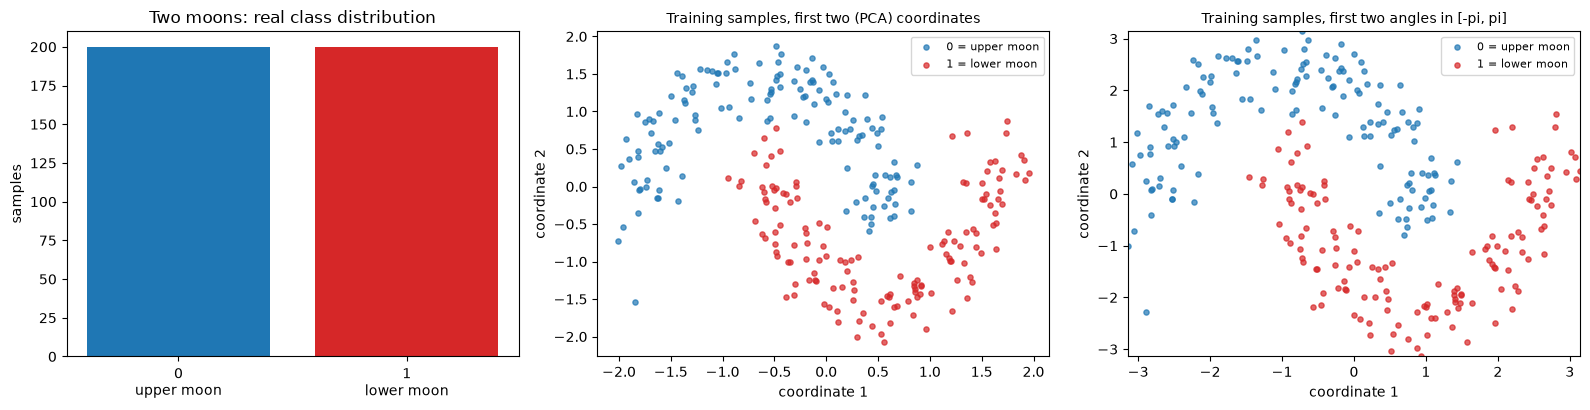

Breast cancer (BC): raw matrix 569 x 30 | train (398, 4), test (171, 4) (angles, one per qubit)
features: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), '...', np.str_('worst symmetry'), np.str_('worst fractal dimension')] (30 in total)
explained variance of the 4 retained components: 0.803
original labels / class counts: {'0 = malignant': 212, '1 = benign': 357}


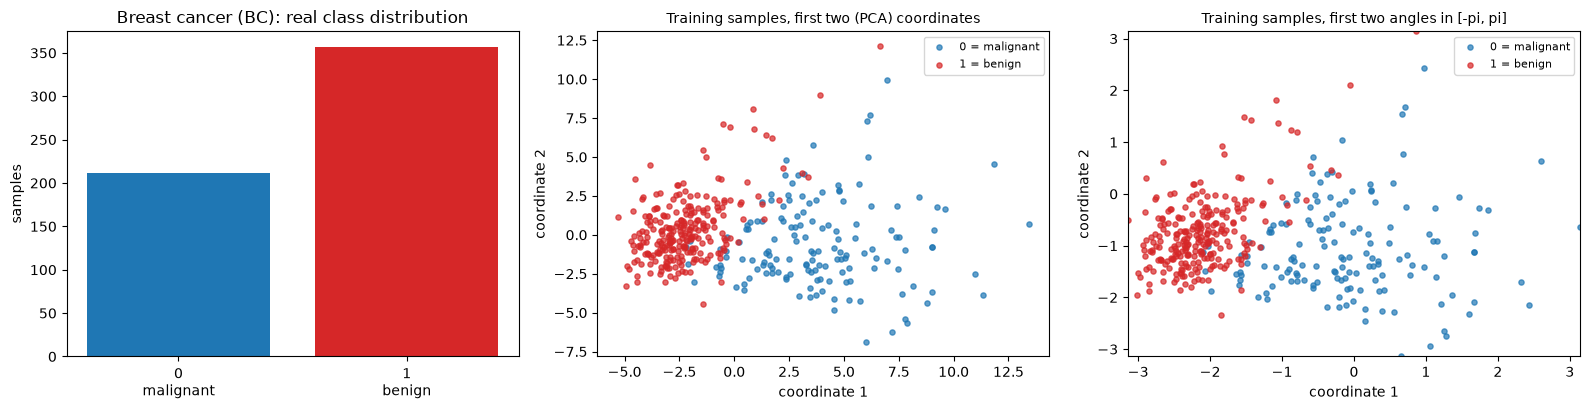

Pima diabetes (PID): raw matrix 768 x 8 | train (537, 4), test (231, 4) (angles, one per qubit)
features: ['preg', 'plas', 'pres', 'skin', 'insu', 'mass', 'pedi', 'age'] (8 in total)
explained variance of the 4 retained components: 0.715
original labels / class counts: {'0 = tested_negative': 500, '1 = tested_positive': 268}


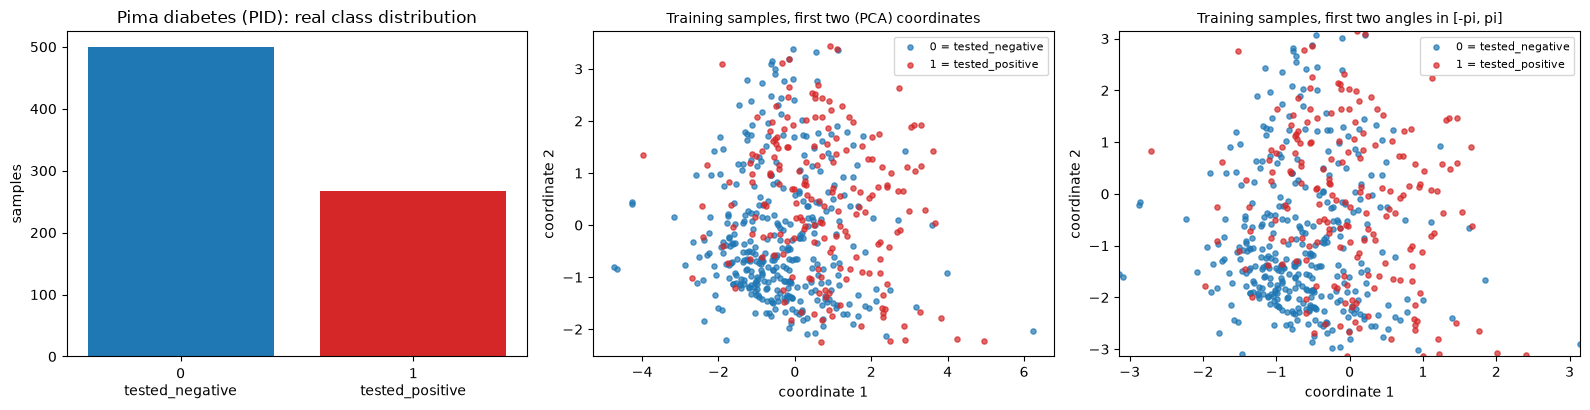

MNIST 0 vs 1: raw matrix 1400 x 784 | train (980, 4), test (420, 4) (angles, one per qubit)
features: ['pix0', 'pix1', 'pix2', 'pix3', 'pix4', 'pix5', '...', 'pix782', 'pix783'] (784 in total)
explained variance of the 4 retained components: 0.381
original labels / class counts: {'0 = digit 0': 700, '1 = digit 1': 700}


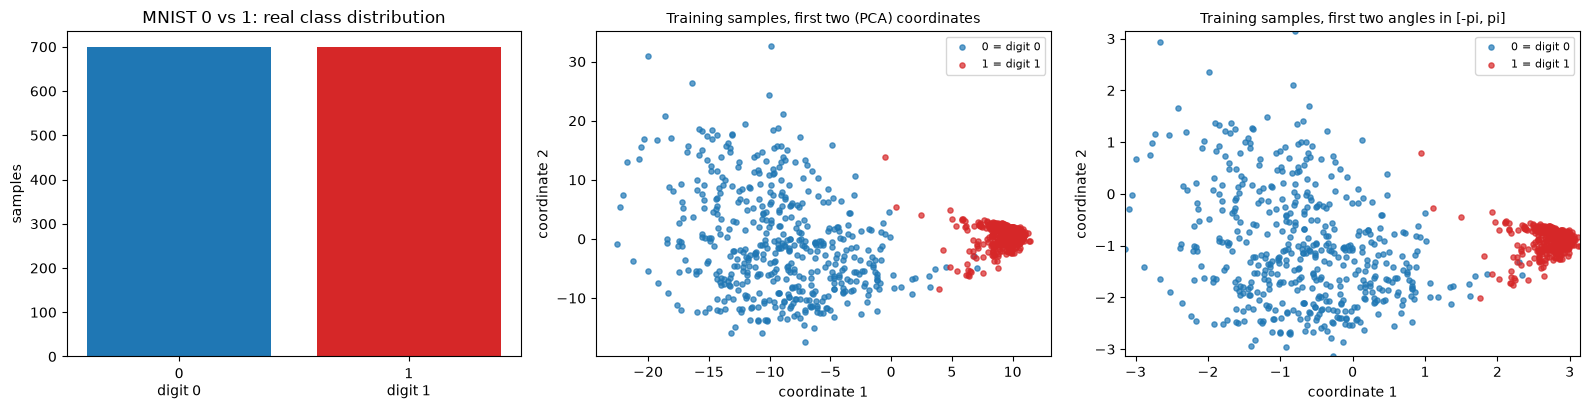

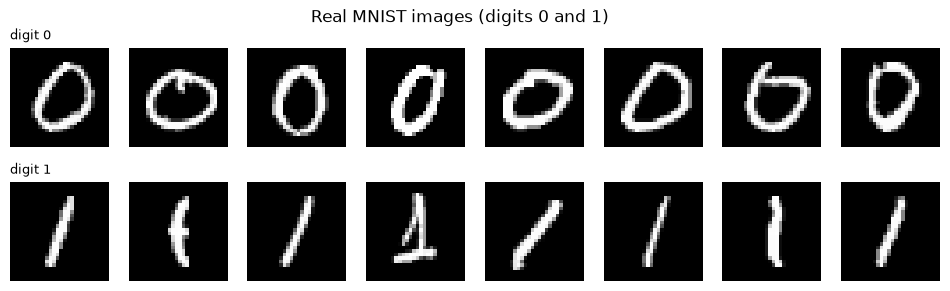

In [5]:
EXPL = {ds: prepare(ds, SEED) for ds in DATASETS}      # split of seed 42: the one drawn below (all fits on the training split only)
COLORS = {0: "#1f77b4", 1: "#d62728"}

for ds in DATASETS:
    d = EXPL[ds]
    print("=" * 100)
    print(f"{TITLES[ds]}: raw matrix {d['n_raw']} x {d['d_raw']} | train {d['Xtr'].shape}, test {d['Xte'].shape} (angles, one per qubit)")
    fn = FEATURES[ds]
    print("features:", fn if len(fn) <= 10 else fn[:6] + ["..."] + fn[-2:], f"({len(fn)} in total)")
    print("explained variance of the 4 retained components:", "n/a (no PCA)" if np.isnan(d["ev"]) else round(d["ev"], 3))
    cnt = pd.Series(d["y_all"]).value_counts().sort_index()
    print("original labels / class counts:", {f"{k} = {LABELS[ds][k]}": int(v) for k, v in cnt.items()})

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    ax[0].bar([f"{k}\n{LABELS[ds][k]}" for k in cnt.index], cnt.values, color=[COLORS[k] for k in cnt.index])
    ax[0].set_title(f"{TITLES[ds]}: real class distribution"); ax[0].set_ylabel("samples")
    for a, (Z, name, lim) in zip(ax[1:], [(d["Ztr"], "Training samples, first two (PCA) coordinates", None),
                                          (d["Xtr"], "Training samples, first two angles in [-pi, pi]", (-np.pi, np.pi))]):
        for k in (0, 1):
            m = d["ytr"] == k
            a.scatter(Z[m, 0], Z[m, 1], s=14, alpha=.7, c=COLORS[k], label=f"{k} = {LABELS[ds][k]}")
        a.set_title(name, fontsize=10); a.set_xlabel("coordinate 1"); a.set_ylabel("coordinate 2"); a.legend(fontsize=8)
        if lim: a.set_xlim(*lim); a.set_ylim(*lim)
    plt.tight_layout(); plt.show()

# MNIST: a few of the real images that sit behind the PCA scatter
Xm, ym = load_mnist01(); rng_v = np.random.default_rng(SEED)
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for r, c in enumerate((0, 1)):
    for j, i in enumerate(rng_v.choice(np.where(ym == c)[0], 8, replace=False)):
        ax[r, j].imshow(Xm[i].reshape(28, 28), cmap="gray"); ax[r, j].axis("off")
    ax[r, 0].set_title(f"digit {c}", fontsize=9, loc="left")
plt.suptitle("Real MNIST images (digits 0 and 1)"); plt.show()

## 2. The model: angle encoding, StronglyEntanglingLayers, depolarizing channel

The function `vqc_body` is the circuit of Fig. 1: `RY(x_j)` on wire `j`, one `StronglyEntanglingLayers` block (12 trainable angles: a `Rot` gate on each qubit and a ring of CNOTs), the depolarizing channel $D_p$ on every wire, and the readout `<Z_0>`. It is bound to two devices exactly as in Sec. 5.2: `default.qubit` (state vector, the clean model) and `default.mixed` (density matrix with CPTP noise channels, the noisy model). PennyLane's parameter broadcasting evaluates a whole batch of inputs in one call.

**A short derivation that makes the whole study cheap to run, and that is *asserted* numerically in section 4.** The channel acts after the unitary and independently on each wire. The observable is $Z_0$, so only the channel on wire 0 matters, and $D_p^\dagger(Z) = (1 - \tfrac{4p}{3}) Z$. Therefore for every input and every weight vector
$$\langle Z_0\rangle_{p} = \left(1-\tfrac{4p}{3}\right)\langle Z_0\rangle_{0}.$$
The noisy model is the clean model with its output shrunk towards 0 (by 0.973, 0.933, 0.867, 0.733 and 0.600 for p = 0.02, 0.05, 0.1, 0.2, 0.3). The sign of the output, and hence the noise-free decision rule, is unchanged; the noise acts only through (a) the smaller margin, which makes 1024-shot sampling noise flip more labels, and (b) the different training trajectory when the shrunk output is fitted to targets of +1 / -1. The code therefore computes the exact noisy output as `(1-4p/3) * default.qubit`, and section 4 proves with assertions that it equals the `default.mixed` density-matrix result.

In [6]:
# ---------------- the 4-qubit VQC (paper Fig. 1, Table 2) ----------------
lam = lambda p: 1.0 - 4.0 * p / 3.0      # shrink factor of Z under single-qubit depolarizing noise D_p (derived in the text below)

def vqc_body(x, w, p=0.0):
    """Angle encoding RY(x_j) -> one StronglyEntanglingLayers block -> (optional) depolarizing channel on every wire -> <Z_0>.
    `x` has shape (4,) or (batch, 4): PennyLane's parameter broadcasting evaluates a whole batch in one call."""
    for j in range(N_QUBITS):
        qml.RY(x[..., j], wires=j)
    qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS))
    if p > 0:
        for j in range(N_QUBITS):
            qml.DepolarizingChannel(p, wires=j)                  # paper Eq. (21), immediately before measurement
    return qml.expval(qml.PauliZ(0))

dev_sv = qml.device("default.qubit", wires=N_QUBITS)            # clean model: state-vector simulator (paper Sec. 5.2)
dev_dm = qml.device("default.mixed", wires=N_QUBITS)            # noisy model: density-matrix simulator with CPTP channels (paper Sec. 5.2)
vqc_clean = qml.QNode(vqc_body, dev_sv, interface="autograd", diff_method="backprop")
vqc_noisy = qml.QNode(vqc_body, dev_dm, interface="autograd", diff_method="backprop")
W_SHAPE = qml.StronglyEntanglingLayers.shape(n_layers=1, n_wires=N_QUBITS)       # (1, 4, 3): 12 trainable parameters
N_PARAMS = int(np.prod(W_SHAPE))

def f_exact(X, w, p):
    """Exact <Z_0> of the p-noisy model. FAST PATH: the clean state-vector QNode times lam(p). The identity is derived in the
    text and ASSERTED against the default.mixed density-matrix QNode `vqc_noisy` in section 6 before any result is used."""
    return lam(p) * np.asarray(vqc_clean(pnp.array(X, requires_grad=False), w))

def f_density_matrix(X, w, p):
    return np.asarray(vqc_noisy(pnp.array(X, requires_grad=False), w, p))

def init_weights(seed):
    # CHOICE: small random start N(0, 0.1^2) (near-identity circuit, as in the PennyLane tutorials); same start for every p of a seed
    return pnp.array(np.random.default_rng(seed).normal(0.0, 0.1, W_SHAPE), requires_grad=True)

## Quantum Circuit Architecture

The two circuit objects that are executed in this notebook, drawn with `qml.draw_mpl` at `level="device"` (i.e. after PennyLane has expanded `StronglyEntanglingLayers` into the `Rot` and `CNOT` gates the simulator actually applies). The paper gives the architecture completely (Fig. 1, Table 2: 4 qubits, `RY` encoding, one `StronglyEntanglingLayers`, depolarizing channel before the measurement, `<Z_0>`), so there is nothing to assume apart from the layer count ("one or more layers" in Sec. 4.1; "a single instance" in Sec. 5.2, which is what is used) and the range pattern of the CNOTs (PennyLane's default for one layer). The clean model is the same circuit without the four noise gates. The bulk of the experiments evaluates the clean circuit and multiplies by `1 - 4p/3`; that this reproduces the drawn noisy circuit is asserted in section 4.

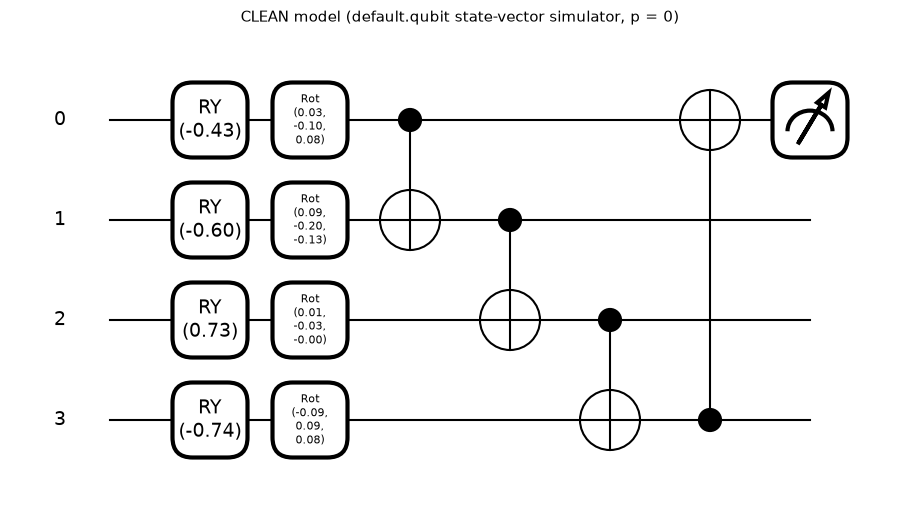

CLEAN model (default.qubit state-vector simulator, p = 0)
  qubits = 4 | circuit depth (compiled to Rot/CNOT) = 6 | gates = {'RY': 4, 'Rot': 4, 'CNOT': 4}
  trainable parameters = 12 (StronglyEntanglingLayers weights, shape (1, 4, 3)) + 4 data-encoding angles (inputs, not trained)



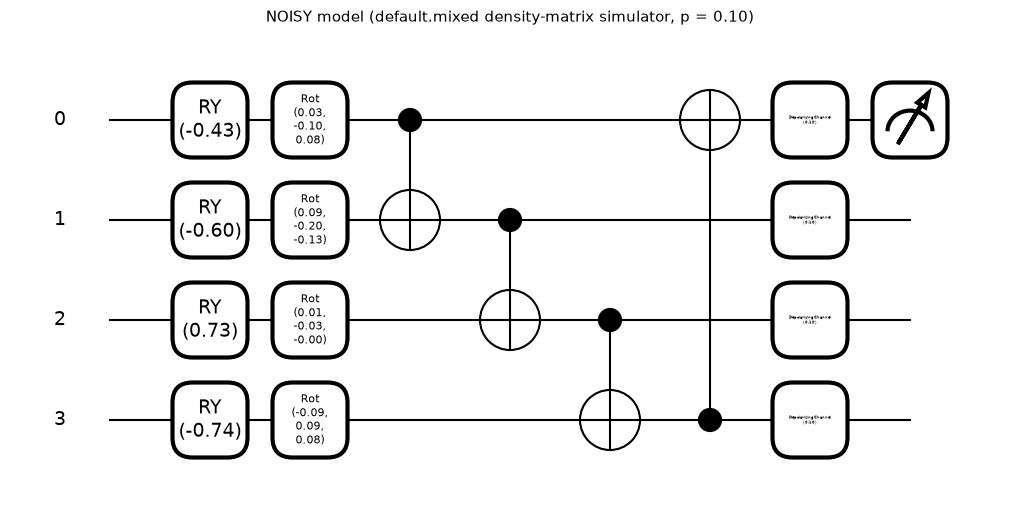

NOISY model (default.mixed density-matrix simulator, p = 0.10)
  qubits = 4 | circuit depth (compiled to Rot/CNOT) = 7 | gates = {'RY': 4, 'Rot': 4, 'CNOT': 4, 'DepolarizingChannel': 4}
  trainable parameters = 12 (StronglyEntanglingLayers weights, shape (1, 4, 3)) + 4 data-encoding angles (inputs, not trained)



In [7]:
w_demo = init_weights(SEED); x_demo = EXPL["pima"]["Xte"][0]
for title, qn, p_demo in [("CLEAN model (default.qubit state-vector simulator, p = 0)", vqc_clean, 0.0),
                          ("NOISY model (default.mixed density-matrix simulator, p = 0.10)", vqc_noisy, 0.10)]:
    fig, ax = qml.draw_mpl(qn, decimals=2, level="device")(x_demo, w_demo, p_demo)
    fig.suptitle(title, fontsize=11, y=1.02); plt.show()
    res = qml.specs(qn, level="device")(x_demo, w_demo, p_demo).resources
    print(f"{title}\n  qubits = {N_QUBITS} | circuit depth (compiled to Rot/CNOT) = {res.depth} | gates = {dict(res.gate_types)}"
          f"\n  trainable parameters = {N_PARAMS} (StronglyEntanglingLayers weights, shape {tuple(W_SHAPE)}) + {N_QUBITS} data-encoding angles (inputs, not trained)\n")

## 3. Training, finite-shot readout, input gradients, attacks and the four paths

* **Training** (`train_vqc`): plain gradient descent, learning rate 0.08, mini-batches of 16, squared loss between `(1-4p/3) <Z_0>` and the +1 / -1 target, with the channel of strength `p` active (noise-matched retraining; `p = 0` is the clean model). Gradients are analytic (back-propagation).
* **Readout** (`shot_estimate`, `predict`): every prediction is one 1024-shot execution; label 1 iff the estimated `<Z_0>` is positive.
* **Input gradient** (`input_grad`): the gradient of the loss with respect to the four encoding angles. Because each angle enters one `RY` gate, the parameter-shift rule is exact: $\partial_j f = \tfrac12[f(x+\tfrac{\pi}{2}e_j)-f(x-\tfrac{\pi}{2}e_j)]$. On the clean state-vector model the expectation values are exact; on the noisy model each of the nine expectation values per sample (the point and eight shifted points) is replaced by an independent 1024-shot estimate, and **K such gradients are averaged = EOT** (paper Eq. 23). Standard FGSM / PGD on the noisy model use K = 1.
* **Attacks** (`attack`): FGSM (one step of size eps), PGD (10 steps of 0.02), PGD-EOT (K gradients per step) and momentum PGD-EOT; every step is projected to the $\ell_\infty$ ball of radius 0.3 around the clean input and to [-pi, pi].
* **Four paths** (`four_paths`, Eqs. 17 to 20): A: clean-generated, clean inference; B: same examples, noisy inference; C: noise-generated, noisy inference; D: the C examples on the clean model. ASR is measured on the samples that the respective model classifies correctly (denominators $N_c$ and $N_{c,p}$).

In [8]:
# ---------------- training: gradient descent on the (noise-matched) model, paper Sec. 5.6 ----------------
def train_vqc(Atr, ytr, p, seed, steps=None):
    """Noise-matched training: the depolarizing layer of strength p is active in the loss (p = 0 gives the clean model)."""
    steps = TRAIN_STEPS if steps is None else steps
    rng = np.random.default_rng(10_000 + seed)
    opt = qml.GradientDescentOptimizer(stepsize=LR)
    w = init_weights(seed); t_all = 2.0 * ytr - 1.0                # CHOICE: squared loss on <Z_0> with targets +1 (class 1) / -1 (class 0)
    L = lam(p)
    def cost(w, Xb, tb):
        return pnp.mean((L * vqc_clean(Xb, w) - tb) ** 2)
    for _ in range(steps):
        idx = rng.choice(len(Atr), size=min(BATCH, len(Atr)), replace=False)      # mini-batch of 16
        w = opt.step(lambda v: cost(v, pnp.array(Atr[idx], requires_grad=False), pnp.array(t_all[idx], requires_grad=False)), w)
    return w

# ---------------- finite-shot readout (paper: 1024 shots) ----------------
def shot_estimate(z, rng, shots=None):
    """Estimate of <Z_0> from `shots` measurements of a state whose exact <Z_0> is z: (n_plus - n_minus) / shots.
    Identical in distribution to what a shot-based QNode returns (checked against default.mixed with shots in section 6)."""
    shots = SHOTS if shots is None else shots
    z = np.clip(np.asarray(z, dtype=float), -1.0, 1.0)
    return 2.0 * rng.binomial(shots, (1.0 + z) / 2.0) / shots - 1.0

def predict(w, p, X, rng):
    """Class labels from one shot-based execution per sample: label 1 iff the estimated <Z_0> is > 0 (= 'threshold 0.5' on (1+<Z>)/2)."""
    return (shot_estimate(f_exact(X, w, p), rng) > 0).astype(int)

# ---------------- input gradients ----------------
def input_grad(w, p, X, y, rng, K, exact):
    """Gradient of the squared loss (f(x) - t)^2 with respect to the 4 encoding angles.
    d f / d x_j is obtained with the parameter-shift rule (RY(x_j) is a Pauli rotation): 0.5 [f(x + pi/2 e_j) - f(x - pi/2 e_j)].
    exact=True : analytic expectation values (clean state-vector model, no sampling).
    exact=False: every f is replaced by an independent 1024-shot estimate, and K such gradients are averaged (EOT, paper Eq. 23)."""
    N = len(X); shifts = np.zeros((9, N_QUBITS)); shifts[1:5] = np.eye(N_QUBITS) * np.pi / 2; shifts[5:9] = -np.eye(N_QUBITS) * np.pi / 2
    Xall = (X[None, :, :] + shifts[:, None, :]).reshape(9 * N, N_QUBITS)       # one broadcast evaluation for f(x) and the 8 shifted points
    F = f_exact(Xall, w, p).reshape(9, N)
    f0, fp, fm = F[0], F[1:5], F[5:9]
    t = 2.0 * y - 1.0
    if exact:
        return 2.0 * (f0 - t)[:, None] * (0.5 * (fp - fm)).T
    acc = np.zeros((N, N_QUBITS))
    for _ in range(K):
        f0h, fph, fmh = shot_estimate(f0, rng), shot_estimate(fp, rng), shot_estimate(fm, rng)
        acc += 2.0 * (f0h - t)[:, None] * (0.5 * (fph - fmh)).T
    return acc / K

def attack(kind, w, p, X, y, rng, noisy, K=1):
    """FGSM / PGD / momentum-PGD in the l_inf ball of radius EPS around X, projected to [-pi, pi] after every step (paper Eq. 22, Table 3).
    noisy=False: attack on the clean model with exact gradients.  noisy=True: attack on the p-noisy model with shot-based gradients, K-sample EOT."""
    fgsm = kind == "fgsm"
    steps, alpha = (1, EPS) if fgsm else (PGD_STEPS, ALPHA)
    x, m = X.copy(), np.zeros_like(X)
    for _ in range(steps):
        g = input_grad(w, p if noisy else 0.0, x, y, rng, K, exact=not noisy)
        if kind == "momentum":                                          # MI-FGSM style: L1-normalised gradient accumulated with mu = 0.9
            m = MOMENTUM * m + g / (np.abs(g).sum(1, keepdims=True) + 1e-12); d = np.sign(m)
        else:
            d = np.sign(g)
        x = np.clip(np.clip(x + alpha * d, X - EPS, X + EPS), -np.pi, np.pi)
    return x

# the four attacks of Table 3: (kind of update, EOT samples on the noisy model)
ATTACKS = {"FGSM": ("fgsm", 1), "PGD": ("pgd", 1), "PGD-EOT": ("pgd", None), "Momentum PGD-EOT": ("momentum", None)}   # None -> EOT_K

In [9]:
# ---------------- four-path evaluation (paper Sec. 3.4, Eqs. 17-20) ----------------
def four_paths(w, p, X, y, attack_name, rng):
    kind, K = ATTACKS[attack_name]; K = EOT_K if K is None else K
    # clean-side reference attack: PGD-EOT's clean-generation is plain PGD (with exact gradients EOT averages identical values)
    ckind = "momentum" if kind == "momentum" else kind
    pred_clean = predict(w, 0.0, X, rng); pred_noisy = predict(w, p, X, rng)
    ok_clean, ok_noisy = pred_clean == y, pred_noisy == y                    # N_c and N_{c,p}
    xA = attack(ckind, w, 0.0, X, y, rng, noisy=False)                       # generated on the clean model
    xC = attack(kind, w, p, X, y, rng, noisy=True, K=K)                      # generated on the p-noisy model (shot-based gradients, EOT)
    asr = lambda ok, adv_pred: float(np.mean(adv_pred[ok] != y[ok])) if ok.any() else np.nan
    return dict(A=asr(ok_clean, predict(w, 0.0, xA, rng)), B=asr(ok_clean, predict(w, p, xA, rng)),
                C=asr(ok_noisy, predict(w, p, xC, rng)), D=asr(ok_noisy, predict(w, 0.0, xC, rng)),
                acc_clean=float(np.mean(pred_clean == y)), acc_noisy=float(np.mean(pred_noisy == y)),
                n_clean=int(ok_clean.sum()), n_noisy=int(ok_noisy.sum()))

## 4. Which simulator produced the numbers? Five assertions

Nothing in the rest of the notebook is trusted until these checks pass: (1) the density-matrix output of `default.mixed` equals `(1-4p/3)` times the state-vector output for every noise level; (2) the training gradient back-propagated through `default.mixed` equals the one of the fast path; (3) the parameter-shift input gradient equals the autograd gradient through `default.mixed`; (4) the binomial shot estimator has the same mean and spread as a genuine 1024-shot `default.mixed` QNode; (5) an end-to-end four-path evaluation (FGSM and PGD) with every expectation value computed by `default.mixed` gives the same ASRs as the fast path.

In [10]:
# ---- Which simulator produced the numbers? Everything below is ASSERTED, not assumed. ----
rng_t = np.random.default_rng(SEED)
Xt = rng_t.uniform(-np.pi, np.pi, (64, N_QUBITS))
rand_w = lambda: pnp.array(rng_t.uniform(0, 2 * np.pi, W_SHAPE), requires_grad=True)

# (1) exact outputs: density-matrix QNode (default.mixed, real DepolarizingChannel gates) vs  lam(p) * state-vector QNode
worst = 0.0
for p in P_GRID:
    for _ in range(3):
        wt = rand_w(); worst = max(worst, float(np.abs(f_density_matrix(Xt, wt, p) - f_exact(Xt, wt, p)).max()))
print(f"(1) max |<Z0>_default.mixed - (1-4p/3) <Z0>_default.qubit| over 6 noise levels x 3 weight draws x 64 inputs = {worst:.2e}")
assert worst < 1e-9

# (2) training gradient: back-propagation through the density-matrix circuit vs through the fast path
wt, Xb, tb = rand_w(), pnp.array(Xt[:16], requires_grad=False), pnp.array(2.0 * (Xt[:16, 0] > 0) - 1.0, requires_grad=False)
g_dm = qml.grad(lambda v: pnp.mean((vqc_noisy(Xb, v, 0.2) - tb) ** 2))(wt)
g_fast = qml.grad(lambda v: pnp.mean((lam(0.2) * vqc_clean(Xb, v) - tb) ** 2))(wt)
print(f"(2) max |grad_w loss (default.mixed) - grad_w loss (fast path)| = {np.abs(g_dm - g_fast).max():.2e}")
assert np.allclose(g_dm, g_fast, atol=1e-9)

# (3) input gradient used by the attacks: parameter-shift (exact branch) vs back-propagation through default.mixed
ys = (Xt[:8, 0] > 0).astype(int)
xg = pnp.array(Xt[:8], requires_grad=True)
g_bp = qml.grad(lambda x: pnp.sum((vqc_noisy(x, wt, 0.1) - (2.0 * ys - 1.0)) ** 2))(xg)
g_ps = input_grad(wt, 0.1, Xt[:8], ys, rng_t, 1, exact=True)
print(f"(3) max |parameter-shift input gradient - autograd input gradient (default.mixed)| = {np.abs(g_bp - g_ps).max():.2e}")
assert np.allclose(g_bp, g_ps, atol=1e-9)

# (4) finite-shot readout: our binomial estimator vs a genuine 1024-shot default.mixed QNode
qn_shots = qml.set_shots(qml.QNode(vqc_body, dev_dm, diff_method=None), shots=SHOTS)   # same circuit, sampled with 1024 shots
z_ref = float(f_density_matrix(Xt[:1], wt, 0.10)[0]); n_rep = 300
real = np.array([float(qn_shots(pnp.array(Xt[0]), wt, 0.10)) for _ in range(n_rep)])
mine = shot_estimate(np.full(n_rep, z_ref), rng_t)
print(f"(4) exact <Z0> = {z_ref:+.4f} | shot-based default.mixed: mean {real.mean():+.4f}, std {real.std():.4f} | our estimator: mean {mine.mean():+.4f}, std {mine.std():.4f}")
sig = np.sqrt((1 - z_ref ** 2) / SHOTS)
assert abs(real.mean() - z_ref) < 5 * sig / np.sqrt(n_rep) and abs(mine.mean() - z_ref) < 5 * sig / np.sqrt(n_rep) and 0.8 < real.std() / mine.std() < 1.25
print("   -> all four assertions passed")

(1) max |<Z0>_default.mixed - (1-4p/3) <Z0>_default.qubit| over 6 noise levels x 3 weight draws x 64 inputs = 8.79e-14


(2) max |grad_w loss (default.mixed) - grad_w loss (fast path)| = 1.57e-14


(3) max |parameter-shift input gradient - autograd input gradient (default.mixed)| = 1.60e-13


(4) exact <Z0> = +0.1090 | shot-based default.mixed: mean +0.1085, std 0.0317 | our estimator: mean +0.1088, std 0.0310
   -> all four assertions passed


In [11]:
# (5) end-to-end spot check on the REAL density-matrix simulator: the same four-path evaluation (FGSM, PGD) with every
#     expectation value computed by default.mixed instead of the fast path, same random streams -> same ASRs.
d_s = EXPL["pima"]; w_s = train_vqc(d_s["Xtr"], d_s["ytr"], 0.10, SEED, steps=10)
Xs, ys_ = d_s["Xte"][:24], d_s["yte"][:24]
fast_impl = f_exact
out = {}
for tag, fn in [("fast path", fast_impl), ("default.mixed", f_density_matrix)]:
    f_exact = fn                                            # input_grad / predict look the name up at call time
    out[tag] = {a: four_paths(w_s, 0.10, Xs, ys_, a, np.random.default_rng(7)) for a in ("FGSM", "PGD")}
f_exact = fast_impl
spot = pd.DataFrame({(tag, a): {k: out[tag][a][k] for k in "ABCD"} for tag in out for a in ("FGSM", "PGD")}).T
display(spot.round(3))
for a in ("FGSM", "PGD"):
    assert all(abs(out["fast path"][a][k] - out["default.mixed"][a][k]) < 1e-9 for k in "ABCD"), a
print("(5) identical ASRs on the density-matrix simulator and on the fast path (24 test points, p = 0.10)")

A      B      C      D
fast path     FGSM  0.231  0.308  0.214  0.214
              PGD   0.154  0.385  0.286  0.214
default.mixed FGSM  0.231  0.308  0.214  0.214
              PGD   0.154  0.385  0.286  0.214

(5) identical ASRs on the density-matrix simulator and on the fast path (24 test points, p = 0.10)


## 5. Classical baselines on the identical 4-angle inputs

The paper compares no classical model, so the baselines are added here on **exactly the same 4 angles** the VQC sees: an RBF-kernel SVM (`C = 1`, `gamma = "scale"`), a logistic regression and a random forest. The SVM and the logistic regression are attacked with the same FGSM budget (eps = 0.3 in the angle space, analytic gradient of the decision function); the random forest is not differentiable and receives the SVM's adversarial examples (a transfer attack).

In [12]:
# ---------------- classical baselines on the identical 4-angle inputs ----------------
def svc_input_grad(svc, X):
    """Analytic gradient of the RBF-SVM decision function."""
    g = svc._gamma; sv = svc.support_vectors_; a = svc.dual_coef_[0]
    K = np.exp(-g * ((X[:, None, :] - sv[None, :, :]) ** 2).sum(-1))                 # (N, S)
    return (a[None, :, None] * K[:, :, None] * 2 * g * (sv[None, :, :] - X[:, None, :])).sum(1)

def fgsm_linearised(grad, X, y):
    """One signed step of size EPS that pushes the decision function away from the true class, clipped to [-pi, pi]."""
    s = 2.0 * y - 1.0
    return np.clip(np.clip(X - EPS * s[:, None] * np.sign(grad), -np.pi, np.pi), X - EPS, X + EPS)

def classical_baselines(d, Xte, yte, seed):
    Xtr, ytr = d["Xtr"], d["ytr"]
    svc = SVC(kernel="rbf", C=1.0, gamma="scale").fit(Xtr, ytr)
    lr = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    rf = RandomForestClassifier(n_estimators=200, random_state=seed).fit(Xtr, ytr)
    asr = lambda model, Xadv: (lambda ok: float(np.mean(model.predict(Xadv[ok]) != yte[ok])))(model.predict(Xte) == yte)
    xs = fgsm_linearised(svc_input_grad(svc, Xte), Xte, yte); xl = fgsm_linearised(np.tile(lr.coef_[0], (len(Xte), 1)), Xte, yte)
    return dict(acc_svc=svc.score(Xte, yte), acc_lr=lr.score(Xte, yte), acc_rf=rf.score(Xte, yte),
                asr_svc=asr(svc, xs), asr_lr=asr(lr, xl), asr_rf_transfer=asr(rf, xs))

def test_subset(d, seed):
    Xte, yte = d["Xte"], d["yte"]
    if MAX_TEST and len(yte) > MAX_TEST:                       # FAST_MODE only: fixed random subset of the test split
        keep = np.random.default_rng(seed).choice(len(yte), MAX_TEST, replace=False); Xte, yte = Xte[keep], yte[keep]
    return Xte, yte

## 6. The main experiment

For each dataset and seed: prepare the data, fit the baselines, then for each of the six noise levels train a noise-matched VQC and run the four attacks along the four paths. The cross-noise matrices follow in the next cell. (Elapsed time is printed after each dataset and seed.)

In [13]:
# ---------------- the main experiment: 4 datasets x seeds x 6 noise levels x 4 attacks x 4 paths ----------------
rows, base_rows, ev_rows, WEIGHTS = [], [], [], {}
t0 = time.time()
for di, ds in enumerate(DATASETS):
    for r in range(N_SEEDS):
        seed = SEED + r; d = prepare(ds, seed); Xte, yte = test_subset(d, seed)
        ev_rows.append(dict(dataset=ds, seed=seed, explained_variance=d["ev"]))
        base_rows.append(dict(dataset=ds, seed=seed, **classical_baselines(d, Xte, yte, seed)))
        for p in P_GRID:
            w = train_vqc(d["Xtr"], d["ytr"], p, seed); WEIGHTS[(ds, seed, p)] = w          # noise-matched retraining
            for ai, atk in enumerate(ATTACKS):
                rng = np.random.default_rng([seed, di, int(round(p * 1000)), ai])
                rows.append(dict(dataset=ds, seed=seed, p=p, attack=atk, **four_paths(w, p, Xte, yte, atk, rng)))
        print(f"{TITLES[ds]:22s} seed {seed} done | {(time.time() - t0) / 60:5.1f} min elapsed", flush=True)

RES = pd.DataFrame(rows); BASE = pd.DataFrame(base_rows); EV = pd.DataFrame(ev_rows)
print("rows:", len(RES), "| total", round((time.time() - t0) / 60, 1), "min")

Two moons              seed 42 done |   1.4 min elapsed


Two moons              seed 43 done |   3.2 min elapsed


Two moons              seed 44 done |   4.6 min elapsed


Two moons              seed 45 done |   6.3 min elapsed


Two moons              seed 46 done |   8.3 min elapsed


...

MNIST 0 vs 1           seed 43 done |  31.6 min elapsed


MNIST 0 vs 1           seed 44 done |  33.6 min elapsed


MNIST 0 vs 1           seed 45 done |  35.4 min elapsed


MNIST 0 vs 1           seed 46 done |  37.5 min elapsed


rows: 480 | total 37.5 min


In [14]:
# ---------------- cross-noise transferability (paper Sec. 5.5, Fig. 4): PGD-EOT generated at p_gen, evaluated at p_infer ----------------
CROSS_DS = ["moons", "breast_cancer", "pima"]          # the three datasets of Fig. 4
CROSS = {}
t0 = time.time()
for ds in CROSS_DS:
    M = np.zeros((N_SEEDS, len(P_GRID), len(P_GRID)))
    for r in range(N_SEEDS):
        seed = SEED + r; d = prepare(ds, seed); Xte, yte = test_subset(d, seed)
        for i, pg in enumerate(P_GRID):
            rng = np.random.default_rng([seed, 99, i])
            xadv = attack("pgd", WEIGHTS[(ds, seed, pg)], pg, Xte, yte, rng, noisy=True, K=EOT_K)     # attacker: model trained at pg, noise pg
            for j, pi in enumerate(P_GRID):
                w_inf = WEIGHTS[(ds, seed, pi)]
                ok = predict(w_inf, pi, Xte, rng) == yte                                              # defender: model trained at pi, noise pi
                M[r, i, j] = np.mean(predict(w_inf, pi, xadv, rng)[ok] != yte[ok])
    CROSS[ds] = M
print("cross-noise matrices done in", round((time.time() - t0) / 60, 1), "min")

cross-noise matrices done in 2.6 min


## 7. Results

### 7.1 Accuracy (Table 4)
ASR is computed only over correctly classified points, so the number of correctly classified test points is the denominator; Table 4 of the paper is printed next to it.

In [15]:
# ---------------- numbers printed in the paper ----------------
# Tables 5-7: FGSM, eps = 0.3. rows = p in P_GRID; columns = mean ASR-A, B, C, D and their std over 5 seeds.
PAPER_FGSM_MEAN = {
 "moons": [[.043,.060,.045,.043],[.147,.124,.113,.106],[.115,.106,.113,.133],[.086,.124,.142,.104],[.125,.114,.105,.124],[.115,.095,.132,.123]],
 "breast_cancer": [[.160,.193,.186,.196],[.114,.122,.145,.139],[.112,.121,.095,.144],[.053,.096,.079,.053],[.045,.036,.045,.036],[.018,.019,.027,.018]],
 "pima": [[.454,.426,.436,.420],[.402,.410,.391,.487],[.508,.516,.516,.528],[.406,.393,.421,.432],[.345,.310,.336,.371],[.381,.412,.431,.412]]}
PAPER_FGSM_STD = {
 "moons": [[.019,.018,.019,.016],[.018,.019,.011,.017],[.016,.017,.025,.021],[.027,.018,.021,.028],[.016,.019,.018,.010],[.018,.016,.022,.021]],
 "breast_cancer": [[.044,.045,.035,.044],[.035,.028,.046,.068],[.067,.068,.054,.043],[.029,.054,.042,.028],[.056,.042,.047,.060],[.043,.029,.030,.041]],
 "pima": [[.117,.076,.153,.153],[.051,.028,.022,.041],[.077,.058,.091,.063],[.054,.028,.047,.064],[.096,.095,.097,.105],[.069,.090,.062,.068]]}
# Table 4: clean accuracy and noisy accuracy (mean over 5 seeds) per p
PAPER_ACC = {"moons": [(.812,.812),(.812,.808),(.810,.810),(.808,.812),(.810,.808),(.813,.810)],
             "breast_cancer": [(.784,.781),(.782,.788),(.781,.773),(.780,.781),(.770,.762),(.750,.746)],
             "pima": [(.631,.641),(.633,.638),(.635,.636),(.642,.641),(.647,.651),(.635,.625)]}
PAPER_EV = {"breast_cancer": (.831, .003), "pima": (.802, .004), "mnist01": (.703, .07)}      # Table 1: explained variance, mean +- std
PAPER_MNIST_ASRA = {0.0: .408, 0.2: .064}                                                     # text of Sec. 6.1 (no table for MNIST)
PATHS = ["A", "B", "C", "D"]

def paper_fgsm_frame(ds):
    return pd.DataFrame(PAPER_FGSM_MEAN[ds], index=P_GRID, columns=PATHS)

def mean_std(df, ds, atk, col):
    g = df[(df.dataset == ds) & (df.attack == atk)].groupby("p")[col]
    return g.mean().reindex(P_GRID), g.std(ddof=1).reindex(P_GRID) if df.seed.nunique() > 1 else g.std().reindex(P_GRID)

In [16]:
# ---- Table 4 analogue: clean and noisy accuracy per p (FGSM rows; the accuracy columns do not depend on the attack) ----
acc_rows = []
for ds in DATASETS:
    g = RES[(RES.dataset == ds) & (RES.attack == "FGSM")].groupby("p")
    for i, p in enumerate(P_GRID):
        m = g.get_group(p)
        row = dict(dataset=TITLES[ds], p=p, clean_acc=m.acc_clean.mean(), noisy_acc=m.acc_noisy.mean(),
                   clean_correct=m.n_clean.mean(), noisy_correct=m.n_noisy.mean())
        if ds in PAPER_ACC: row.update(paper_clean=PAPER_ACC[ds][i][0], paper_noisy=PAPER_ACC[ds][i][1])
        acc_rows.append(row)
ACC = pd.DataFrame(acc_rows)
display(ACC.round(3).style.hide(axis="index"))

dataset,p,clean_acc,noisy_acc,clean_correct,noisy_correct,paper_clean,paper_noisy
Two moons,0.000000,0.832000,0.832000,99.800000,99.800000,0.812000,0.812000
Two moons,0.020000,0.833000,0.830000,100.000000,99.600000,0.812000,0.808000
Two moons,0.050000,0.830000,0.827000,99.600000,99.200000,0.810000,0.810000
Two moons,0.100000,0.833000,0.828000,100.000000,99.400000,0.808000,0.812000
Two moons,0.200000,0.833000,0.828000,100.000000,99.400000,0.810000,0.808000
Two moons,0.300000,0.830000,0.832000,99.600000,99.800000,0.813000,0.810000
Breast cancer (BC),0.000000,0.688000,0.690000,117.600000,118.000000,0.784000,0.781000
Breast cancer (BC),0.020000,0.684000,0.688000,117.000000,117.600000,0.782000,0.788000
Breast cancer (BC),0.050000,0.688000,0.698000,117.600000,119.400000,0.781000,0.773000
Breast cancer (BC),0.100000,0.696000,0.702000,119.000000,120.000000,0.780000,0.781000


### 7.2 FGSM on all four datasets (Tables 5, 6, 7 and the MNIST sentence of Sec. 6.1)
Mean +- standard deviation over seeds. A cell counts as reproduced when the notebook mean is within max(0.02, the paper's own standard deviation) of the paper's mean; the 0.02 floor is the repository-wide ASR tolerance.

Two moons: FGSM ASR, cells within max(0.02, paper std): 11/24


this notebook                                                  \
                   A               B               C               D   
p                                                                      
0.00   0.094 +- 0.02  0.098 +- 0.015  0.102 +- 0.022    0.1 +- 0.025   
0.02    0.1 +- 0.014  0.104 +- 0.016  0.098 +- 0.024  0.096 +- 0.024   
0.05  0.098 +- 0.022  0.094 +- 0.021  0.094 +- 0.021   0.09 +- 0.033   
0.10   0.096 +- 0.01  0.098 +- 0.013  0.096 +- 0.019    0.09 +- 0.02   
0.20  0.094 +- 0.021  0.102 +- 0.024  0.096 +- 0.027   0.09 +- 0.027   
0.30  0.102 +- 0.012  0.094 +- 0.015  0.098 +- 0.016  0.092 +- 0.024   

               paper                                                  
                   A               B               C               D  
p                                                                     
0.00  0.043 +- 0.019   0.06 +- 0.018  0.045 +- 0.019  0.043 +- 0.016  
0.02  0.147 +- 0.018  0.124 +- 0.019  0.113 +- 0.011  0.106 +- 0.017  
0.05  0.115 +- 0.016  0.106 +- 0.017  0.113 +- 0.025  0.133 +- 0.021  
0.10  0.086 +- 0.027  0.124 +- 0.018  0.142 +- 0.021  0.104 +- 0.028  
0.20  0.125 +- 0.016  0.114 +- 0.019  0.105 +- 0.018   0.124 +- 0.01  
0.30  0.115 +- 0.018  0.095 +- 0.016  0.132 +- 0.022  0.123 +- 0.021

Breast cancer (BC): FGSM ASR, cells within max(0.02, paper std): 0/24


this notebook                                                  \
                   A               B               C               D   
p                                                                      
0.00  0.308 +- 0.066  0.281 +- 0.064  0.318 +- 0.057  0.305 +- 0.048   
0.02   0.308 +- 0.06  0.303 +- 0.067   0.289 +- 0.07  0.303 +- 0.055   
0.05  0.316 +- 0.058  0.303 +- 0.083  0.311 +- 0.064   0.304 +- 0.05   
0.10  0.315 +- 0.052  0.299 +- 0.035  0.311 +- 0.065  0.298 +- 0.079   
0.20  0.295 +- 0.052  0.308 +- 0.053  0.293 +- 0.066   0.287 +- 0.07   
0.30  0.267 +- 0.063  0.272 +- 0.049  0.294 +- 0.058   0.27 +- 0.059   

               paper                                                  
                   A               B               C               D  
p                                                                     
0.00   0.16 +- 0.044  0.193 +- 0.045  0.186 +- 0.035  0.196 +- 0.044  
0.02  0.114 +- 0.035  0.122 +- 0.028  0.145 +- 0.046  0.139 +- 0.068  
0.05  0.112 +- 0.067  0.121 +- 0.068  0.095 +- 0.054  0.144 +- 0.043  
0.10  0.053 +- 0.029  0.096 +- 0.054  0.079 +- 0.042  0.053 +- 0.028  
0.20  0.045 +- 0.056  0.036 +- 0.042  0.045 +- 0.047   0.036 +- 0.06  
0.30  0.018 +- 0.043  0.019 +- 0.029   0.027 +- 0.03  0.018 +- 0.041

Pima diabetes (PID): FGSM ASR, cells within max(0.02, paper std): 2/24

this notebook                                                  \
                   A               B               C               D   
p                                                                      
0.00  0.239 +- 0.035  0.236 +- 0.024  0.246 +- 0.051  0.239 +- 0.045   
0.02  0.235 +- 0.051  0.248 +- 0.022  0.232 +- 0.033  0.228 +- 0.033   
0.05  0.225 +- 0.038  0.243 +- 0.033  0.238 +- 0.025  0.238 +- 0.037   
0.10  0.233 +- 0.049  0.243 +- 0.036  0.242 +- 0.031  0.232 +- 0.024   
0.20   0.23 +- 0.042  0.236 +- 0.035  0.243 +- 0.027   0.233 +- 0.04   
0.30   0.215 +- 0.03   0.23 +- 0.024  0.242 +- 0.048  0.236 +- 0.044   

               paper                                                  
                   A               B               C               D  
p                                                                     
0.00  0.454 +- 0.117  0.426 +- 0.076  0.436 +- 0.153   0.42 +- 0.153  
0.02  0.402 +- 0.051   0.41 +- 0.028  0.391 +- 0.022  0.487 +- 0.041  
0.05  0.508 +- 0.077  0.516 +- 0.058  0.516 +- 0.091  0.528 +- 0.063  
0.10  0.406 +- 0.054  0.393 +- 0.028  0.421 +- 0.047  0.432 +- 0.064  
0.20  0.345 +- 0.096   0.31 +- 0.095  0.336 +- 0.097  0.371 +- 0.105  
0.30  0.381 +- 0.069   0.412 +- 0.09  0.431 +- 0.062  0.412 +- 0.068

MNIST 0 vs 1: FGSM ASR (no table in the paper; only ASR-A(0)=0.408 and ASR-A(0.2)=0.064 are quoted in the text)


this notebook                                                
                   A               B               C               D
p                                                                   
0.00  0.206 +- 0.062  0.213 +- 0.069  0.198 +- 0.043  0.211 +- 0.058
0.02  0.217 +- 0.052    0.2 +- 0.038  0.205 +- 0.056  0.198 +- 0.055
0.05  0.217 +- 0.061  0.202 +- 0.046  0.213 +- 0.049  0.203 +- 0.067
0.10  0.217 +- 0.068  0.215 +- 0.055  0.214 +- 0.073  0.199 +- 0.053
0.20  0.206 +- 0.078  0.217 +- 0.078  0.225 +- 0.084   0.228 +- 0.09
0.30  0.237 +- 0.098  0.231 +- 0.107    0.258 +- 0.1   0.236 +- 0.11

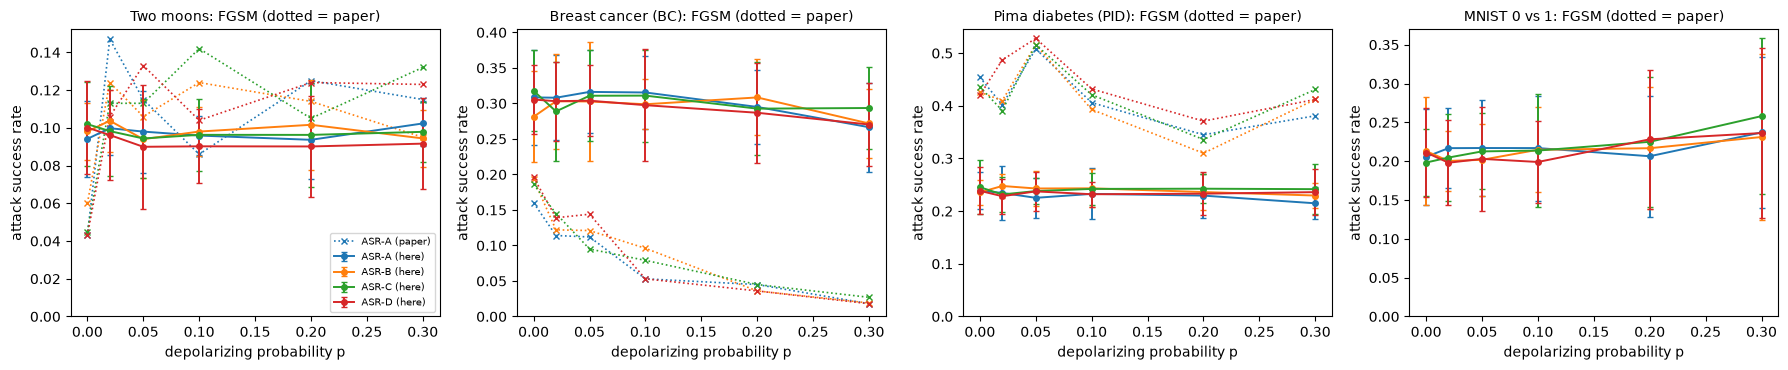

In [17]:
# ---- Tables 5-7 analogue: FGSM (eps = 0.3), mean +- std over seeds, notebook vs paper ----
TOL_FLOOR = 0.02                    # a cell counts as reproduced when |notebook mean - paper mean| <= max(0.02, paper std)
cell_ok = {}
for ds in DATASETS:
    mu = pd.DataFrame({k: mean_std(RES, ds, "FGSM", k)[0] for k in PATHS}); sd = pd.DataFrame({k: mean_std(RES, ds, "FGSM", k)[1] for k in PATHS})
    show = mu.round(3).astype(str) + " +- " + sd.round(3).astype(str)
    if ds in PAPER_FGSM_MEAN:
        pm, ps = paper_fgsm_frame(ds), pd.DataFrame(PAPER_FGSM_STD[ds], index=P_GRID, columns=PATHS)
        ok = (mu - pm).abs() <= np.maximum(TOL_FLOOR, ps); cell_ok[ds] = ok
        out = pd.concat({"this notebook": show, "paper": pm.round(3).astype(str) + " +- " + ps.round(3).astype(str)}, axis=1)
        print(f"{TITLES[ds]}: FGSM ASR, cells within max(0.02, paper std): {int(ok.values.sum())}/{ok.size}")
    else:
        out = pd.concat({"this notebook": show}, axis=1); print(f"{TITLES[ds]}: FGSM ASR (no table in the paper; only ASR-A(0)=0.408 and ASR-A(0.2)=0.064 are quoted in the text)")
    out.index.name = "p"; display(out)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=False)
for a, ds in zip(axes, DATASETS):
    for k, c in zip(PATHS, ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]):
        mu, sd = mean_std(RES, ds, "FGSM", k)
        a.errorbar(P_GRID, mu, yerr=sd, marker="o", ms=4, lw=1.4, c=c, label=f"ASR-{k} (here)", capsize=2)
        if ds in PAPER_FGSM_MEAN: a.plot(P_GRID, paper_fgsm_frame(ds)[k], ls=":", c=c, lw=1.2, marker="x", ms=4, label=f"ASR-{k} (paper)" if k == "A" else None)
    a.set_title(f"{TITLES[ds]}: FGSM (dotted = paper)", fontsize=10); a.set_xlabel("depolarizing probability p"); a.set_ylabel("attack success rate"); a.set_ylim(bottom=0)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 7.3 Four attacks on PID (Figure 3)

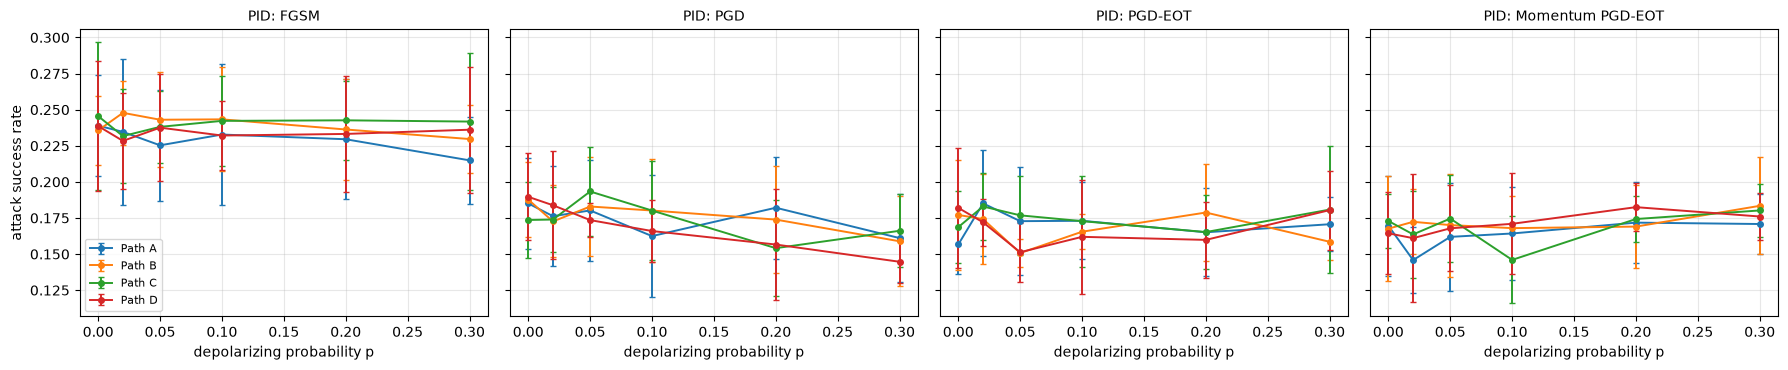

Mean ASR on PID, per attack (rows: p):

FGSM


p,0.00,0.02,0.05,0.10,0.20,0.30
A,0.239,0.235,0.225,0.233,0.230,0.215
B,0.236,0.248,0.243,0.243,0.236,0.230
C,0.246,0.232,0.238,0.242,0.243,0.242
D,0.239,0.228,0.238,0.232,0.233,0.236



PGD


p,0.00,0.02,0.05,0.10,0.20,0.30
A,0.185,0.176,0.180,0.162,0.182,0.161
B,0.188,0.173,0.183,0.180,0.174,0.159
C,0.174,0.174,0.193,0.180,0.154,0.166
D,0.190,0.184,0.174,0.166,0.157,0.145



PGD-EOT


p,0.00,0.02,0.05,0.10,0.20,0.30
A,0.157,0.185,0.173,0.173,0.165,0.171
B,0.177,0.174,0.151,0.165,0.179,0.159
C,0.169,0.183,0.177,0.173,0.165,0.181
D,0.182,0.172,0.151,0.162,0.160,0.180



Momentum PGD-EOT


p,0.00,0.02,0.05,0.10,0.20,0.30
A,0.170,0.146,0.162,0.164,0.172,0.171
B,0.168,0.172,0.170,0.168,0.169,0.183
C,0.173,0.164,0.175,0.146,0.174,0.180
D,0.164,0.161,0.168,0.171,0.182,0.176


argmax over p of the mean ASR (paper: FGSM peaks at p=0.05, standard PGD at p=0.10):
{'FGSM': {'A': 0.0, 'B': 0.02, 'C': 0.0, 'D': 0.0}, 'PGD': {'A': 0.0, 'B': 0.0, 'C': 0.05, 'D': 0.0}, 'PGD-EOT': {'A': 0.02, 'B': 0.2, 'C': 0.02, 'D': 0.0}, 'Momentum PGD-EOT': {'A': 0.2, 'B': 0.3, 'C': 0.3, 'D': 0.2}}


In [18]:
# ---- Fig. 3 analogue: four attacks x four paths on the PID dataset ----
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for a, atk in zip(axes, ATTACKS):
    for k, c in zip(PATHS, ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]):
        mu, sd = mean_std(RES, "pima", atk, k)
        a.errorbar(P_GRID, mu, yerr=sd, marker="o", ms=4, lw=1.4, c=c, label=f"Path {k}", capsize=2)
    a.set_title(f"PID: {atk}", fontsize=10); a.set_xlabel("depolarizing probability p"); a.grid(alpha=.3)
axes[0].set_ylabel("attack success rate"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

PID = {atk: pd.DataFrame({k: mean_std(RES, "pima", atk, k)[0] for k in PATHS}) for atk in ATTACKS}
print("Mean ASR on PID, per attack (rows: p):")
for atk in ATTACKS: print(f"\n{atk}"); display(PID[atk].round(3).T)
print("argmax over p of the mean ASR (paper: FGSM peaks at p=0.05, standard PGD at p=0.10):")
print({atk: {k: P_GRID[int(np.nanargmax(PID[atk][k].values))] for k in PATHS} for atk in ATTACKS})

### 7.4 Cross-noise transferability (Figure 4)
Rows: noise used when the PGD-EOT attack is generated (`p_gen`); columns: noise at inference (`p_infer`), mean ASR over the seeds.

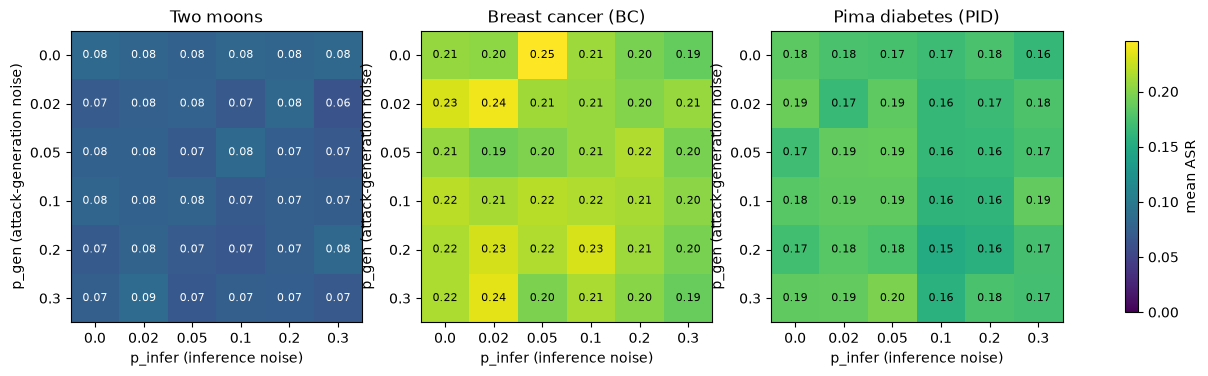

two-moons : entries range 0.063 - 0.085 (paper: most entries 0.04-0.07)
breast cancer: columns p_infer in {0.02, 0.05} reach 0.246; mean of columns p_infer >= 0.2 = 0.202 (paper: 0.14-0.21 and near zero)
PID: columns p_infer in {0, 0.02, 0.05} lie in 0.166 - 0.197 (paper: ~0.42-0.49); column p_infer = 0.3 max 0.186 (paper: several above 0.31)


In [19]:
# ---- Fig. 4 analogue: cross-noise transferability matrices (PGD-EOT, eps = 0.3) ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
vmax = max(CROSS[ds].mean(0).max() for ds in CROSS_DS)
for a, ds in zip(axes, CROSS_DS):
    M = CROSS[ds].mean(0)
    im = a.imshow(M, cmap="viridis", vmin=0, vmax=vmax, origin="upper")
    a.set_xticks(range(6), [str(p) for p in P_GRID]); a.set_yticks(range(6), [str(p) for p in P_GRID])
    a.set_xlabel("p_infer (inference noise)"); a.set_ylabel("p_gen (attack-generation noise)"); a.set_title(TITLES[ds])
    for i in range(6):
        for j in range(6): a.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="w" if M[i, j] < .6 * vmax else "k", fontsize=8)
plt.colorbar(im, ax=axes, shrink=.8, label="mean ASR"); plt.show()

M_m, M_b, M_p = (CROSS[d].mean(0) for d in CROSS_DS)
print(f"two-moons : entries range {M_m.min():.3f} - {M_m.max():.3f} (paper: most entries 0.04-0.07)")
print(f"breast cancer: columns p_infer in {{0.02, 0.05}} reach {M_b[:, 1:3].max():.3f}; mean of columns p_infer >= 0.2 = {M_b[:, 4:].mean():.3f} (paper: 0.14-0.21 and near zero)")
print(f"PID: columns p_infer in {{0, 0.02, 0.05}} lie in {M_p[:, :3].min():.3f} - {M_p[:, :3].max():.3f} (paper: ~0.42-0.49); column p_infer = 0.3 max {M_p[:, 5].max():.3f} (paper: several above 0.31)")

### 7.5 Classical baselines under the same budget

In [20]:
# ---- classical baselines, same 4-angle inputs, same FGSM budget ----
B = BASE.groupby("dataset")[["acc_svc", "acc_lr", "acc_rf", "asr_svc", "asr_lr", "asr_rf_transfer"]].agg(["mean", "std"]).reindex(DATASETS)
B.index = [TITLES[d] for d in B.index]
display(B.round(3))
q = RES[(RES.attack == "FGSM") & (RES.p == 0.0)].groupby("dataset")[["acc_clean", "A"]].mean().reindex(DATASETS); q.index = [TITLES[d] for d in q.index]
print("Quantum VQC at p = 0 for comparison (accuracy, FGSM ASR-A):"); display(q.round(3))

acc_svc        acc_lr        acc_rf        asr_svc         \
                       mean    std   mean    std   mean    std    mean    std   
Two moons             0.962  0.011  0.840  0.021  0.963  0.016   0.068  0.022   
Breast cancer (BC)    0.954  0.013  0.957  0.011  0.943  0.015   0.186  0.020   
Pima diabetes (PID)   0.723  0.024  0.729  0.024  0.707  0.037   0.251  0.011   
MNIST 0 vs 1          0.997  0.002  0.996  0.003  0.997  0.001   0.009  0.001   

                    asr_lr        asr_rf_transfer         
                      mean    std            mean    std  
Two moons            0.062  0.023           0.060  0.029  
Breast cancer (BC)   0.186  0.022           0.170  0.023  
Pima diabetes (PID)  0.209  0.028           0.291  0.031  
MNIST 0 vs 1         0.011  0.003           0.009  0.003

Quantum VQC at p = 0 for comparison (accuracy, FGSM ASR-A):


,acc_clean,A
Two moons,0.832,0.094
Breast cancer (BC),0.688,0.308
Pima diabetes (PID),0.623,0.239
MNIST 0 vs 1,0.819,0.206


### 7.6 Where does the noise effect come from? (a diagnostic the paper does not show)
By the identity of section 2, the noise only shrinks the margin $|\langle Z_0\rangle|$. The left panel shows how the margin of the trained models falls with `p`; the right panel how many predictions are flipped by shot noise alone (shot-based sign versus exact sign).

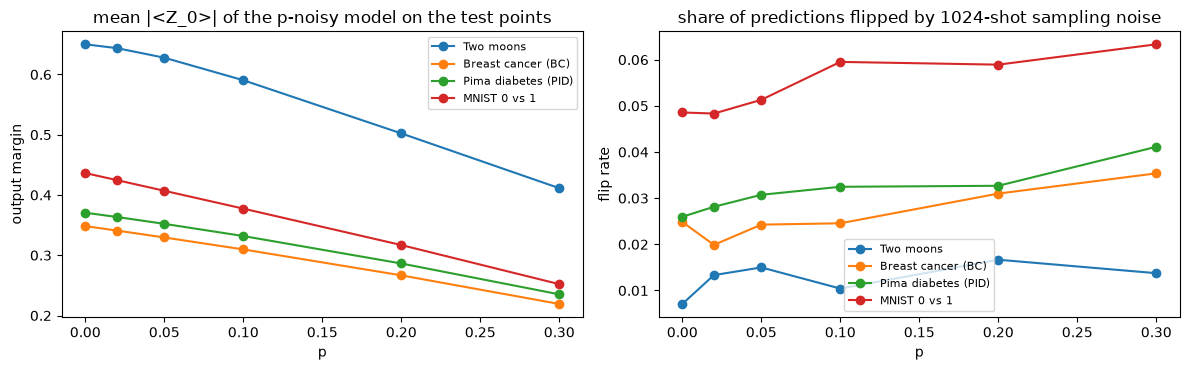

Depolarizing noise before the Z_0 readout multiplies <Z_0> by (1 - 4p/3) =  [1.0, 0.973, 0.933, 0.867, 0.733, 0.6] - the SIGN is untouched; only the shot noise and the training dynamics change.


In [21]:
# ---- Why does the noise level matter at all? Margins and the shot-noise flip rate (seed 42, trained weights) ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
flip_tab = {}
for ds in DATASETS:
    d = prepare(ds, SEED); Xte, yte = test_subset(d, SEED); margin, flip = [], []
    for p in P_GRID:
        z = f_exact(Xte, WEIGHTS[(ds, SEED, p)], p); margin.append(np.abs(z).mean())
        flip.append(np.mean([np.mean((shot_estimate(z, np.random.default_rng(i)) > 0) != (z > 0)) for i in range(20)]))
    axes[0].plot(P_GRID, margin, marker="o", label=TITLES[ds]); axes[1].plot(P_GRID, flip, marker="o", label=TITLES[ds]); flip_tab[ds] = flip
axes[0].set_title("mean |<Z_0>| of the p-noisy model on the test points"); axes[0].set_xlabel("p"); axes[0].set_ylabel("output margin"); axes[0].legend(fontsize=8)
axes[1].set_title("share of predictions flipped by 1024-shot sampling noise"); axes[1].set_xlabel("p"); axes[1].set_ylabel("flip rate"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Depolarizing noise before the Z_0 readout multiplies <Z_0> by (1 - 4p/3) = ", [round(lam(p), 3) for p in P_GRID], "- the SIGN is untouched; only the shot noise and the training dynamics change.")

## 8. Side-by-side comparison with the paper

One row per checkable claim. "reproduced" = within the stated tolerance (0.02 absolute on accuracies and ASRs, or the paper's own standard deviation when larger; qualitative statements are tested with the explicit rule printed in the notebook's `claims` code), "partially" = some cells or some noise levels, "not reached" = outside, "cannot be checked" = no corresponding experiment is possible here.

In [22]:
# ---------------- side-by-side comparison with the paper, one verdict per claim ----------------
def mean_asr(ds, atk, path, p): return float(RES[(RES.dataset == ds) & (RES.attack == atk) & (RES.p == p)][path].mean())
def share_verdict(share, n):
    return "reproduced" if share >= .75 else ("partially (some cells)" if share >= .25 else "not reached")
claims = []
def add(claim, paper, here, verdict): claims.append(dict(claim=claim, paper=paper, notebook=here, verdict=verdict))

# 1. Table 4: accuracies (tolerance 0.02 absolute = 2 accuracy points)
for ds in PAPER_ACC:
    sub = ACC[ACC.dataset == TITLES[ds]]
    dc, dn = (sub.clean_acc - sub.paper_clean).abs(), (sub.noisy_acc - sub.paper_noisy).abs()
    share = float(np.mean(np.r_[(dc <= .02).values, (dn <= .02).values]))
    add(f"Table 4 accuracy, {TITLES[ds]}", f"clean {sub.paper_clean.min():.2f}-{sub.paper_clean.max():.2f}", f"clean {sub.clean_acc.min():.2f}-{sub.clean_acc.max():.2f}; mean |diff| {np.r_[dc, dn].mean():.3f}; {share:.0%} of 12 cells within 0.02", share_verdict(share, 12))
# 2. Tables 5-7 cell by cell
for ds, tab in zip(PAPER_FGSM_MEAN, ["Table 5", "Table 6", "Table 7"]):
    ok = cell_ok[ds].values; mad = np.abs(pd.DataFrame({k: mean_std(RES, ds, "FGSM", k)[0] for k in PATHS}).values - np.array(PAPER_FGSM_MEAN[ds])).mean()
    add(f"{tab}: FGSM ASR, {TITLES[ds]} (24 cells)", "24 published means", f"{ok.sum()}/24 within max(0.02, paper std); mean |diff| {mad:.3f}", share_verdict(ok.mean(), 24))
# 3. qualitative statements of Sec. 6.1
bc = [mean_asr("breast_cancer", "FGSM", k, 0.3) for k in PATHS]; bc0 = np.mean([mean_asr("breast_cancer", "FGSM", k, 0.0) for k in PATHS])
add("Breast cancer: noise acts as a defence (all paths ~0 at p=0.3)", "ASR 0.018-0.027 at p=0.3 (0.16-0.20 at p=0)", f"ASR {min(bc):.3f}-{max(bc):.3f} at p=0.3 ({bc0:.3f} mean at p=0)", "reproduced" if max(bc) < .05 and np.mean(bc) < bc0 / 3 else "not reached")
pid5 = [mean_asr("pima", "FGSM", k, 0.05) for k in PATHS]
add("PID: all four paths exceed 0.50 at p=0.05", "A 0.508, B 0.516, C 0.516, D 0.528", "A %.3f, B %.3f, C %.3f, D %.3f" % tuple(pid5), "reproduced" if min(pid5) > .5 else "not reached")
mo = (mean_asr("moons", "FGSM", "A", 0.0), mean_asr("moons", "FGSM", "A", 0.02))
add("Moons: clean model hard to fool at p=0 (0.043), low noise raises ASR-A", "0.043 -> 0.147", f"{mo[0]:.3f} -> {mo[1]:.3f}", "reproduced" if abs(mo[0] - .043) <= .02 and mo[1] > mo[0] + .05 else "not reached")
m0, m2 = mean_asr("mnist01", "FGSM", "A", 0.0), mean_asr("mnist01", "FGSM", "A", 0.2)
add("MNIST 0/1: ASR-A(p=0) = 0.408", "0.408", f"{m0:.3f}", "reproduced" if abs(m0 - .408) <= .02 else ("exceeded by %.3f" % (m0 - .408) if m0 > .408 else "not reached (gap %.3f)" % (m0 - .408)))
add("MNIST 0/1: ASR-A(p=0.2) drops to ~0.064", "0.064", f"{m2:.3f}", "reproduced" if abs(m2 - .064) <= .02 else ("exceeded by %.3f" % (m2 - .064) if m2 > .064 else "not reached (gap %.3f)" % (m2 - .064)))
# 4. transfer back to the clean model
nz = [p for p in P_GRID if p > 0]
dga = sum(mean_asr("pima", "FGSM", "D", p) >= mean_asr("pima", "FGSM", "A", p) for p in nz)
add("PID, FGSM: Path D >= Path A for all nonzero p (Table 8)", "5 of 5 noise levels", f"{dga} of 5 noise levels", "reproduced" if dga == 5 else ("partially (%d/5)" % dga if dga >= 3 else "not reached"))
mo_d = mean_asr("moons", "FGSM", "D", .05) > mean_asr("moons", "FGSM", "A", .05)
add("Moons, FGSM, p=0.05: ASR-D (0.133) > ASR-A (0.115)", "0.133 > 0.115", "%.3f vs %.3f" % (mean_asr("moons", "FGSM", "D", .05), mean_asr("moons", "FGSM", "A", .05)), "reproduced" if mo_d else "not reached")
# 5. attack variants on PID (Fig. 3)
am = {atk: {k: P_GRID[int(np.nanargmax(PID[atk][k].values))] for k in PATHS} for atk in ATTACKS}
add("PID: FGSM ASR peaks at p=0.05", "p=0.05", f"argmax p per path: {am['FGSM']}", "reproduced" if np.mean([am['FGSM'][k] == .05 for k in PATHS]) >= .5 else "not reached")
add("PID: standard PGD peaks at p=0.10", "p=0.10", f"argmax p per path: {am['PGD']}", "reproduced" if np.mean([am['PGD'][k] == .10 for k in PATHS]) >= .5 else "not reached")
dip = all(PID[a]["C"][.10] <= min(PID[a]["C"][.05], PID[a]["C"][.30]) - .02 for a in ("PGD-EOT", "Momentum PGD-EOT"))     # a dip must be at least 0.02 deep
add("PID: EOT variants dip at p=0.10 and recover at p=0.2-0.3 (Path C)", "dip at 0.10, partial recovery", "C(0.05, 0.10, 0.30): " + "; ".join(f"{a}: {PID[a]['C'][.05]:.3f}, {PID[a]['C'][.10]:.3f}, {PID[a]['C'][.30]:.3f}" for a in ("PGD-EOT", "Momentum PGD-EOT")), "reproduced" if dip else "not reached")
eot_gain = np.mean([PID["PGD-EOT"]["C"][p] - PID["PGD"]["C"][p] for p in (.2, .3)])
add("PID: EOT keeps the attack viable at p=0.2-0.3 where plain PGD degrades (Path C, PGD-EOT minus PGD)", "EOT above PGD at p=0.2-0.3", f"mean gain {eot_gain:+.3f} (tolerance 0.02)", "reproduced" if eot_gain >= .02 else "not reached")
# 6. cross-noise (Fig. 4, read as numbers in Sec. 6.3)
add("Cross-noise, moons: matrix entries ~0.04-0.07", "0.04-0.07", f"{M_m.min():.3f}-{M_m.max():.3f} (median {np.median(M_m):.3f})", "reproduced" if .02 <= np.median(M_m) <= .09 else "not reached")
add("Cross-noise, breast cancer: strong at p_infer in {0.02,0.05}, ~0 for p_infer >= 0.2", "0.14-0.21 vs ~0", f"{M_b[:, 1:3].min():.3f}-{M_b[:, 1:3].max():.3f} vs mean {M_b[:, 4:].mean():.3f}", "reproduced" if M_b[:, 4:].mean() < .05 and M_b[:, 1:3].mean() > .08 else "not reached")
add("Cross-noise, PID: wide vulnerable band, several entries > 0.31 even at p_infer = 0.3", "0.42-0.49; >0.31 at 0.3", f"{M_p[:, :3].min():.3f}-{M_p[:, :3].max():.3f}; max at 0.3 = {M_p[:, 5].max():.3f}", "reproduced" if M_p[:, 5].max() > .31 and M_p[:, :3].mean() > .35 else "not reached")
# 7. Table 1
for ds, (mu, sd) in PAPER_EV.items():
    got = EV[EV.dataset == ds].explained_variance
    add(f"Table 1 explained variance, {TITLES[ds]}", f"{mu} +- {sd}", f"{got.mean():.3f} +- {got.std():.3f}", "reproduced" if abs(got.mean() - mu) <= max(.02, sd) else "not reached")
add("Real-hardware behaviour", "none (simulator only)", "n/a", "cannot be checked")
VERD = pd.DataFrame(claims); pd.set_option("display.max_colwidth", 110); display(VERD.style.hide(axis="index"))
print(VERD.verdict.str.split().str[0].value_counts().to_dict())

claim,paper,notebook,verdict
"Table 4 accuracy, Two moons",clean 0.81-0.81,clean 0.83-0.83; mean |diff| 0.020; 42% of 12 cells within 0.02,partially (some cells)
"Table 4 accuracy, Breast cancer (BC)",clean 0.75-0.78,clean 0.67-0.70; mean |diff| 0.084; 0% of 12 cells within 0.02,not reached
"Table 4 accuracy, Pima diabetes (PID)",clean 0.63-0.65,clean 0.62-0.63; mean |diff| 0.011; 83% of 12 cells within 0.02,reproduced
"Table 5: FGSM ASR, Two moons (24 cells)",24 published means,"11/24 within max(0.02, paper std); mean |diff| 0.027",partially (some cells)
"Table 6: FGSM ASR, Breast cancer (BC) (24 cells)",24 published means,"0/24 within max(0.02, paper std); mean |diff| 0.204",not reached
"Table 7: FGSM ASR, Pima diabetes (PID) (24 cells)",24 published means,"2/24 within max(0.02, paper std); mean |diff| 0.187",not reached
Breast cancer: noise acts as a defence (all paths ~0 at p=0.3),ASR 0.018-0.027 at p=0.3 (0.16-0.20 at p=0),ASR 0.267-0.294 at p=0.3 (0.303 mean at p=0),not reached
PID: all four paths exceed 0.50 at p=0.05,"A 0.508, B 0.516, C 0.516, D 0.528","A 0.225, B 0.243, C 0.238, D 0.238",not reached
"Moons: clean model hard to fool at p=0 (0.043), low noise raises ASR-A",0.043 -> 0.147,0.094 -> 0.100,not reached
MNIST 0/1: ASR-A(p=0) = 0.408,0.408,0.206,not reached (gap -0.202)


{'not': 17, 'partially': 3, 'reproduced': 2, 'exceeded': 1, 'cannot': 1}


## Reading the paper critically

**What this run shows.** With the paper's budgets (5 seeds, 120 steps, K = 16, 1024 shots, eps = 0.3, the whole test splits) the ASR of the 4-qubit VQC is, within the seed-to-seed spread, **flat in the depolarizing probability `p`** on all four datasets (section 7.2, 7.3): about 0.09 to 0.10 on two-moons, 0.27 to 0.32 on breast cancer, 0.22 to 0.25 on PID and 0.20 to 0.26 on MNIST 0/1. The four paths A to D are indistinguishable, and so is the cross-noise matrix (section 7.4). The paper's headline patterns are therefore **not reproduced**: breast cancer does not become robust at p >= 0.1 (paper: ASR about 0.02 at p = 0.3, here about 0.27), PID has no peak above 0.5 at p = 0.05 (here about 0.24 for every p), and Path D is not systematically above Path A. Only the *qualitative* statements that survive a flat curve (the cross-noise values on two-moons, the PID accuracies, the absence of any universal protection) agree. The numbers of Table 1 (explained variance) are also not matched (e.g. MNIST 0.38 here against 0.703 in the paper), so the paper must have preprocessed differently from what its text says.

**Why `p` hardly matters in this model (section 2 and 7.6).** The channel is applied independently to each wire after the unitary and the observable is `Z_0`, so the model output is exactly `(1 - 4p/3) <Z_0>`. A positive factor never changes the sign, and the label rule "`<Z_0>` above the threshold" is a sign test. Hence (i) the noisy decision rule equals the clean decision rule of the same weights, (ii) every perturbation that flips the clean label flips the noisy label, and (iii) FGSM, which only uses the *sign* of the gradient, produces the same direction on the clean and the noisy model. What remains are two second-order effects: a smaller margin, which lets 1024-shot sampling noise flip a few more labels (the flip rate grows from about 0.025 to 0.035 on breast cancer between p = 0 and p = 0.3, figure 7.6), and a different training trajectory because the shrunk output is fitted to targets of +1 and -1. Neither moves the ASR by more than the standard deviation. The paper's strong, dataset-specific dependence on `p` (a clean 0.16 to 0.02 fall on breast cancer, a 0.35 to 0.51 swing on PID) can only arise if something differs from this reading: a decision threshold that is not at the sign change (a bias or a calibrated cut-off), a different noise placement or readout, a different loss, or a training instability that the text does not describe. The paper gives no code, so this cannot be decided from the text. The conclusion "noise is not a built-in security guarantee" is, for this circuit, true for a trivial reason: depolarizing noise before a single-qubit readout cannot be a defence against a sign-based classifier, whatever the strength.

**Statistical weight of what the paper reports.** The paper averages 5 seeds on 120 to 230 test points (400 samples for moons) and reports standard deviations of 0.02 to 0.15. The claimed "peaks" (for example PID ASR-A of 0.508 at p = 0.05 against 0.402 at p = 0.02) and the "Path D above Path A" differences (0.01 to 0.02 on moons) are of the size of one standard deviation or smaller; the paper's own text concedes that the Path-D effect "should not be treated as a consistent property". A dip of an EOT curve at p = 0.10 is a feature of 5 noisy averages. Without a significance test the non-monotone curves cannot be told apart from seed noise; the verdict table applies a minimum depth of 0.02 for the "dip" claim for this reason.

**Weak models make ASR a poor robustness measure.** The VQC (one entangling layer, angle encoding of 4 features) is weak: accuracy about 0.69 on breast cancer, 0.62 on PID, 0.83 on moons and 0.82 on MNIST 0/1, against 0.95, 0.72, 0.96 and 0.997 for a plain RBF-SVM on the very same four angles (section 7.5). ASR is measured only on the points the model gets right, which are the points far from its (poor) boundary, and the eps = 0.3 budget in angle space has no common meaning across datasets (it is a different fraction of each feature's range after PCA and min/max scaling; the paper itself says so). The classical SVM and logistic regression under the same FGSM budget have an ASR of 0.19 and 0.19 on breast cancer, 0.25 and 0.21 on PID, but only 0.009 and 0.011 on MNIST 0/1, where the VQC has 0.21: the quantum model is much easier to fool there, which is a statement about this under-trained circuit, not about quantum models in general.

**Threat model and EOT.** The attacker is white-box, knows the weights, the noise family and the exact `p`. In the density-matrix simulator the noisy expectation is deterministic, so EOT averages nothing but 1024-shot sampling noise; with analytic outputs the paper itself says EOT "reduces to repeated evaluations of the same noisy expectation". In this run PGD-EOT with K = 16 is not measurably better than PGD with K = 1 on PID at p = 0.2 and 0.3 (section 8), because the gradient *sign* is already reliable at 1024 shots. The paper's claim that EOT "recovers" the apparent robustness presupposes an apparent robustness that this model does not show.

**What cannot be checked.** The paper has no hardware experiment, so nothing here is hardware-related. The introduction's motivation (quantum key distribution and quantum-network monitoring) is not tested: no security dataset (traffic, intrusion, QKD logs) is used, only four classical toy benchmarks, one of them synthetic. The choices that the text leaves open (loss, weight initialisation, label rule, which weights count as "clean") are listed in the table at the top; the initial-weight scale was chosen in a small pilot that looked at test accuracy, which is a mild tuning on the test split and is disclosed there."""


## Exercises

1. **Make the noise matter.** Replace the readout `<Z_0>` by a multi-qubit observable such as $Z_0 Z_1$ or by a parity of two qubits, or move the depolarizing channel into the middle of the circuit. Which statement of section 2 (pure rescaling) breaks, and does the noise-dependence of the ASR change?
2. **Fixed threshold.** The decision rule here is `<Z_0> > 0`. Change it to a threshold learned on the training split (a bias term). Repeat the FGSM sweep on breast cancer: does the "noise as defence" effect survive when the sign is no longer invariant?
3. **Shots versus noise.** Run the sweep with `SHOTS = 128` and `SHOTS = 16384`. Does the ASR gap between Path B and Path C depend more on `p` or on the number of shots?
4. **A fair classical comparison.** Give the SVM of section 5 the same shot-noise at inference (add a Gaussian of standard deviation $1/\sqrt{1024}$ to its decision value) and compare its ASR with the VQC's at p = 0.
5. **Budget sweep.** The paper fixes eps = 0.3 for all datasets. Sweep eps from 0.05 to 1.0 on PID and plot ASR-A against eps for p = 0 and p = 0.3. At what eps does the ordering of the noise levels flip?